# M7 — Final Model Freeze: ECG Beat Review and Annotation Assistant

This notebook freezes the **highest-retained 5-class Macro-F1 model**: M2 Version A, an unweighted Random Forest using 12 reference morphology features + 5 RR features (17 total), 200 trees, `max_features="log2"`, `class_weight=None`, `random_state=42`.

**Why not XGBoost?** M4 XGBoost-unweighted had the highest numerical 5-class Macro-F1 (0.504282), but its paired record-bootstrap improvement over M2 was +0.002567 with 95% CI [-0.004180, +0.009493]. The lower bound was not above zero, so it did not pass the locked retention rule. M2 Version A (0.501716) remains the best retained model and is the model frozen here.

**Calibration policy:** use the M6 isotonic one-vs-rest calibrators for confidence/review probabilities. Keep the Random Forest's original argmax class label; do not silently change the class label when calibration changes the probability ranking. If the calibrated top class disagrees with the Random Forest label, force human review. This protects the selected M2 classification result while exposing the calibration disagreement.

**M6 trade-off:** isotonic had the best reported Log Loss (0.416667) and Macro-Classwise ECE (0.012568), but worse multiclass Brier (0.147247 vs 0.134467 uncalibrated) and Top-label ECE (0.024390 vs 0.020039). The M6 recalculated calibrated-argmax Macro-F1 was 0.405207. Isotonic is therefore a documented deployment choice for confidence support, not a claim that it improves classification or every calibration metric.

**Demo-person limitation:** current M0 folds include all 45 people. No separate untouched demo-person list is available in the saved artifacts. This notebook will not invent one or report training-set scores as a demo test. Performance figures come from saved out-of-fold predictions.

The notebook produces ONE `joblib` pipeline bundle containing the final estimator, calibration maps, confidence thresholds, feature contract and dataset/software metadata; a reusable inference module; pinned dependency versions; a model card; bootstrap tables; and report-ready PNG figures.

**M7 demo-person evaluation limitation:** the currently saved M0 splits assign all 45 people to development/CV. No previously designated demo-person holdout file exists. This notebook does not create a new split or pretend training predictions are a test. It trains on all development people and reports the existing person-grouped OOF evaluation. The M7 demo-person evaluation substep remains unavailable unless a genuine pre-designated holdout is supplied.

## Run instructions

1. Attach the corrected M0/M1 dataset, saved M0 split files, and **M2 Version A** RR table and OOF predictions.
2. Attach the saved M6 notebook output as an optional input if you want the reliability-curve figure and nested calibration artifacts included. It is not required to train the final model; the verified M6 summary values below are also recorded in this notebook.
3. Run once with `RUN_M7_FREEZE = False` and confirm all data/split/feature checks pass.
4. Set `RUN_M7_FREEZE = True`, then **Save Version → Save & Run All (Commit)**.
5. Download `/kaggle/working/ECG_Project/09_M7_FINAL_MODEL_FREEZE/` or `M7_Final_Model_and_Report_Artifacts.zip` generated at the end.

Final selected model: M2 Version A (17 features, unweighted RF), because it is the highest-scoring model that satisfies the locked paired-bootstrap retention rule. The XGBoost numerical lead is exploratory and did not pass that rule.

Required M0/M1 files:
- `MITBIH_MLII_DualLead_Dataset_corrected.csv`
- `validated_reconstructed_beat_table.csv.gz` (or `.csv`)
- `m0_row_fold_membership.csv.gz` (or `.csv`)
- `m0_person_fold_membership.csv`
- `m0_split_fingerprint.txt`

Required M2 Version A files:
- `m2_rr_features_with_sample_positions.csv.gz` (or `.csv`)
- `m2_oof_predictions_REFERENCE_MODEL_PLUS_RR_FEATURES.csv.gz` (or `.csv`)

Optional M6 files (for reliability curves / traceability):
- `m6_oof_predictions_M6_ISOTONIC.csv.gz`
- `m6_oof_predictions_M6_SIGMOID.csv.gz`
- `m6_reliability_curve_summary.csv`
- `m6_nested_fold_audit.csv`

In [1]:
from pathlib import Path
import hashlib
import json
import os
import platform
import sys
import textwrap
import zipfile
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.ensemble import RandomForestClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
    log_loss,
)
import joblib

# ----------------------------- USER CONFIGURATION -----------------------------
RUN_M7_FREEZE = True  # Validate first; set True only after every check passes.
FINAL_CALIBRATION_METHOD = "isotonic"  # Selected deployment calibration method from M6.
TARGET_HIGH_CONFIDENCE_PRECISION = 0.80  # Project review policy, NOT a clinical threshold.
MIN_THRESHOLD_SUPPORT = 30
THRESHOLD_GRID = np.round(np.arange(0.05, 1.001, 0.01), 2)

INPUT_ROOT = Path("/kaggle/input")
OUTPUT_DIR = Path("/kaggle/working/ECG_Project/09_M7_FINAL_MODEL_FREEZE")
FIGURE_DIR = OUTPUT_DIR / "report_figures"
TABLE_DIR = OUTPUT_DIR / "report_tables"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

CLASS_ORDER = ["N", "S", "V", "F", "Q"]
FOUR_CLASS_ORDER = ["N", "S", "V", "Q"]
PROB_COLS = [f"Prob_{c}" for c in CLASS_ORDER]
EXPECTED_COUNTS = {"N": 90341, "S": 2781, "V": 7229, "F": 802, "Q": 3894}
EXPECTED_BEATS = 105047
EXPECTED_RECORDS = 46
EXPECTED_PEOPLE = 45
SAMPLE_RATE_HZ = 360.0
N_SPLITS = 5
N_REPEATS = 5
SEED = 42
TREES = 200
MAX_FEATURES = "log2"
BOOTSTRAP_SAMPLES = 1000
BOOTSTRAP_SEED = 20261105
EXPECTED_SPLIT_FINGERPRINT = "5a07f73452ca78af0b212db5e9f060fc4fcc66f49374c2462249189b847440d9"

SIGNAL_COLS = [f"MLII_{i}" for i in range(201)] + [f"Lead2_{i}" for i in range(201)]
AAMI_MAP = {
    "N": "N", "L": "N", "R": "N", "e": "N", "j": "N",
    "A": "S", "a": "S", "J": "S", "S": "S",
    "V": "V", "E": "V", "F": "F", "/": "Q", "f": "Q", "Q": "Q",
}
RR_FEATURES = [
    "pre_RR", "post_RR", "mean_previous_10_RR",
    "pre_RR_div_mean_previous_10_RR", "post_RR_div_pre_RR",
]
REFERENCE_FEATURE_NAMES = [
    "d1_mean", "d1_std", "d1_max", "d1_min", "d1_abs_mean", "d1_energy",
    "d2_std", "d2_abs_mean", "normalized_median", "normalized_IQR",
    "normalized_q25", "normalized_q75",
]
FEATURE_NAMES = REFERENCE_FEATURE_NAMES + RR_FEATURES
EXPECTED_RR_MISSING = {
    "pre_RR": 716,
    "post_RR": 719,
    "mean_previous_10_RR": 259,
    "pre_RR_div_mean_previous_10_RR": 946,
    "post_RR_div_pre_RR": 1385,
}
EXPECTED_ROWS_WITH_MISSING_RR = 1614

# M6 outputs supplied by the user; kept as verified project results for report plots.
M6_CALIBRATION_SUMMARY = pd.DataFrame([
    {"Experiment": "M2_UNCALIBRATED", "Macro_F1_5_Class": 0.501716, "Macro_F1_4_Class_N_S_V_Q": 0.625019, "Balanced_Accuracy": 0.504764, "Accuracy": 0.910155, "Log_Loss": 0.842139, "Brier_Score": 0.134467, "Macro_Class_Brier": 0.026893, "Macro_Class_ECE": 0.021879, "Top_Label_ECE_10_Bins": 0.020039},
    {"Experiment": "M6_SIGMOID", "Macro_F1_5_Class": 0.406378, "Macro_F1_4_Class_N_S_V_Q": 0.510891, "Balanced_Accuracy": 0.402487, "Accuracy": 0.906655, "Log_Loss": 0.819783, "Brier_Score": 0.157803, "Macro_Class_Brier": 0.031561, "Macro_Class_ECE": 0.012752, "Top_Label_ECE_10_Bins": 0.024252},
    {"Experiment": "M6_ISOTONIC", "Macro_F1_5_Class": 0.405207, "Macro_F1_4_Class_N_S_V_Q": 0.509066, "Balanced_Accuracy": 0.392395, "Accuracy": 0.910050, "Log_Loss": 0.416667, "Brier_Score": 0.147247, "Macro_Class_Brier": 0.029449, "Macro_Class_ECE": 0.012568, "Top_Label_ECE_10_Bins": 0.024390},
])

# Cumulative experiment results supplied by the user in verified M2-M6 outputs.
EXPERIMENT_COMPARISON = pd.DataFrame([
    {"Experiment": "REFERENCE_MODEL (M0)", "Macro_F1_5_Class": 0.435270, "Macro_F1_4_Class_N_S_V_Q": 0.546823, "Status": "Reference baseline"},
    {"Experiment": "M2 Version A (REFERENCE + RR)", "Macro_F1_5_Class": 0.501716, "Macro_F1_4_Class_N_S_V_Q": 0.625019, "Status": "Selected model"},
    {"Experiment": "M2 Version B (REFERENCE + RR)", "Macro_F1_5_Class": 0.499921, "Macro_F1_4_Class_N_S_V_Q": 0.623839, "Status": "Backup; not selected"},
    {"Experiment": "M3 (REFERENCE + RR + TIMING)", "Macro_F1_5_Class": 0.428178, "Macro_F1_4_Class_N_S_V_Q": 0.537024, "Status": "Rejected; measurable degradation"},
    {"Experiment": "M4 RF unweighted", "Macro_F1_5_Class": 0.501716, "Macro_F1_4_Class_N_S_V_Q": 0.625019, "Status": "Reproduced M2"},
    {"Experiment": "M4 RF balanced", "Macro_F1_5_Class": 0.495519, "Macro_F1_4_Class_N_S_V_Q": 0.618575, "Status": "No measurable improvement"},
    {"Experiment": "M4 HGB unweighted", "Macro_F1_5_Class": 0.495094, "Macro_F1_4_Class_N_S_V_Q": 0.611871, "Status": "No measurable improvement"},
    {"Experiment": "M4 HGB balanced", "Macro_F1_5_Class": 0.498377, "Macro_F1_4_Class_N_S_V_Q": 0.619125, "Status": "No measurable improvement"},
    {"Experiment": "M4 XGBoost unweighted", "Macro_F1_5_Class": 0.504282, "Macro_F1_4_Class_N_S_V_Q": 0.628236, "Status": "Highest numerical result; paired CI crosses zero"},
    {"Experiment": "M4 XGBoost balanced", "Macro_F1_5_Class": 0.501482, "Macro_F1_4_Class_N_S_V_Q": 0.623247, "Status": "No measurable improvement"},
    {"Experiment": "M6 sigmoid argmax", "Macro_F1_5_Class": 0.406378, "Macro_F1_4_Class_N_S_V_Q": 0.510891, "Status": "Calibration evaluation; argmax changes"},
    {"Experiment": "M6 isotonic argmax", "Macro_F1_5_Class": 0.405207, "Macro_F1_4_Class_N_S_V_Q": 0.509066, "Status": "Calibration evaluation; argmax changes"},
])

print("PHASE M7 — FINAL MODEL FREEZE")
print("Training enabled:", RUN_M7_FREEZE)
print("Final calibration method:", FINAL_CALIBRATION_METHOD)
print("Output directory:", OUTPUT_DIR)
print("Python:", sys.version.split()[0], "| NumPy:", np.__version__, "| Pandas:", pd.__version__, "| scikit-learn:", sklearn.__version__)


def find_one(filename_options):
    matches = []
    for filename in filename_options:
        matches.extend(p for p in INPUT_ROOT.rglob(filename) if p.is_file())
    matches = sorted(set(matches))
    if len(matches) != 1:
        raise FileNotFoundError(
            f"Expected exactly one file from {filename_options}. Found {len(matches)}:\n" + "\n".join(str(p) for p in matches)
        )
    print("FOUND:", matches[0])
    return matches[0]


def find_optional(filename_options):
    matches = []
    for filename in filename_options:
        matches.extend(p for p in INPUT_ROOT.rglob(filename) if p.is_file())
    matches = sorted(set(matches))
    if len(matches) > 1:
        raise FileNotFoundError(f"More than one optional match for {filename_options}:\n" + "\n".join(str(p) for p in matches))
    return matches[0] if matches else None


def atomic_csv(df, path, **kwargs):
    path = Path(path)
    tmp = path.with_name(path.name + ".tmp")
    df.to_csv(tmp, **kwargs)
    os.replace(tmp, path)


def validate_probability_matrix(prob, name):
    prob = np.asarray(prob, dtype=float)
    if prob.ndim != 2 or prob.shape[1] != len(CLASS_ORDER):
        raise ValueError(f"{name}: expected n x 5 probabilities; got {prob.shape}.")
    if not np.isfinite(prob).all() or (prob < -1e-7).any() or (prob > 1.0 + 1e-7).any():
        raise ValueError(f"{name}: probabilities must be finite and in [0, 1].")
    if not np.allclose(prob.sum(axis=1), 1.0, atol=1e-5):
        raise ValueError(f"{name}: probability rows do not sum to one.")

PHASE M7 — FINAL MODEL FREEZE
Training enabled: True
Final calibration method: isotonic
Output directory: /kaggle/working/ECG_Project/09_M7_FINAL_MODEL_FREEZE
Python: 3.13.18 | NumPy: 2.1.3 | Pandas: 2.3.3 | scikit-learn: 1.6.1


## 1. Verify corrected M0/M1 data, saved splits, and M2 Version A inputs

In [2]:
corrected_path = find_one(["MITBIH_MLII_DualLead_Dataset_corrected.csv"])
beat_table_path = find_one(["validated_reconstructed_beat_table.csv.gz", "validated_reconstructed_beat_table.csv"])
row_path = find_one(["m0_row_fold_membership.csv.gz", "m0_row_fold_membership.csv"])
person_path = find_one(["m0_person_fold_membership.csv"])
fingerprint_path = find_one(["m0_split_fingerprint.txt"])
rr_path = find_one(["m2_rr_features_with_sample_positions.csv.gz", "m2_rr_features_with_sample_positions.csv"])
m2_oof_path = find_one(["m2_oof_predictions_REFERENCE_MODEL_PLUS_RR_FEATURES.csv.gz", "m2_oof_predictions_REFERENCE_MODEL_PLUS_RR_FEATURES.csv"])

DATA = pd.read_csv(corrected_path, low_memory=False)
DATA.columns = [str(c).strip().strip('"').strip("'").strip() for c in DATA.columns]
if DATA.shape != (106870, 404):
    raise ValueError(f"Unexpected corrected dataset shape: {DATA.shape}; expected (106870, 404).")
if any(c not in DATA.columns for c in SIGNAL_COLS):
    raise ValueError("Corrected dataset is missing one or more waveform columns.")
DATA["Record_ID"] = pd.to_numeric(DATA["Record_ID"], errors="raise").astype(int)
DATA["Label"] = DATA["Label"].astype(str).str.strip()
DATA["AAMI_Label"] = DATA["Label"].map(AAMI_MAP)
aami_df = DATA[DATA["AAMI_Label"].isin(CLASS_ORDER)].copy().reset_index(drop=True)
aami_df["Person_ID"] = ["person_201_202" if rid in (201, 202) else f"person_{rid}" for rid in aami_df["Record_ID"].to_numpy()]
aami_df["Row_Index"] = np.arange(len(aami_df), dtype=np.int64)

counts = aami_df["AAMI_Label"].value_counts().reindex(CLASS_ORDER, fill_value=0).to_dict()
assert len(aami_df) == EXPECTED_BEATS, len(aami_df)
assert counts == EXPECTED_COUNTS, counts
assert aami_df["Record_ID"].nunique() == EXPECTED_RECORDS
assert aami_df["Person_ID"].nunique() == EXPECTED_PEOPLE

# Dataset composition tables for the model card/report; these are descriptive counts, not model metrics.
record_class_counts = (
    aami_df.groupby(["Record_ID", "Person_ID", "AAMI_Label"]).size()
    .unstack("AAMI_Label", fill_value=0).reindex(columns=CLASS_ORDER, fill_value=0)
    .reset_index()
)
person_class_counts = (
    aami_df.groupby(["Person_ID", "AAMI_Label"]).size()
    .unstack("AAMI_Label", fill_value=0).reindex(columns=CLASS_ORDER, fill_value=0)
    .reset_index()
)
f_by_person = person_class_counts[["Person_ID", "F"]].sort_values("F", ascending=False)
top2_f_share = float(f_by_person.head(2)["F"].sum() / max(int(person_class_counts["F"].sum()), 1))
atomic_csv(record_class_counts, TABLE_DIR / "m7_class_counts_by_record.csv", index=False)
atomic_csv(person_class_counts, TABLE_DIR / "m7_class_counts_by_person.csv", index=False)
atomic_csv(f_by_person, TABLE_DIR / "m7_f_class_concentration_by_person.csv", index=False)
print(f"F-class share from top two people: {top2_f_share:.4%}")

beat_table = pd.read_csv(beat_table_path, compression="infer", low_memory=False)
beat_table.columns = [str(c).strip().strip('"').strip("'").strip() for c in beat_table.columns]
required_beat_cols = ["Record_ID", "Person_ID", "Sample_Index", "Original_Symbol", "AAMI_Label"] + SIGNAL_COLS
missing_beat_cols = [c for c in required_beat_cols if c not in beat_table.columns]
if missing_beat_cols:
    raise ValueError(f"M1 beat table missing columns: {missing_beat_cols[:20]}")
beat_table["Record_ID"] = pd.to_numeric(beat_table["Record_ID"], errors="raise").astype(int)
beat_table["Sample_Index"] = pd.to_numeric(beat_table["Sample_Index"], errors="raise").astype(np.int64)
for c in ["Person_ID", "Original_Symbol", "AAMI_Label"]:
    beat_table[c] = beat_table[c].astype(str).str.strip()
if len(beat_table) != EXPECTED_BEATS or beat_table[["Record_ID", "Sample_Index"]].duplicated().any():
    raise ValueError("M1 beat table row count or composite-key uniqueness is invalid.")
if not np.array_equal(beat_table["Record_ID"].to_numpy(), aami_df["Record_ID"].to_numpy()):
    raise ValueError("M1 Record_ID row order mismatch.")
if not np.array_equal(beat_table["AAMI_Label"].to_numpy(), aami_df["AAMI_Label"].to_numpy()):
    raise ValueError("M1 AAMI labels do not match corrected dataset.")
if not np.array_equal(beat_table["Person_ID"].to_numpy(), aami_df["Person_ID"].to_numpy()):
    raise ValueError("M1 Person_ID values do not match.")
processed_wave = aami_df[SIGNAL_COLS].to_numpy(dtype=np.float32)
reconstructed_wave = beat_table[SIGNAL_COLS].to_numpy(dtype=np.float32)
if not np.array_equal(processed_wave, reconstructed_wave):
    mismatch = np.argwhere(processed_wave != reconstructed_wave)[0].tolist()
    raise ValueError(f"M1 waveform alignment failed. First mismatch: {mismatch}")
aami_df["Sample_Index"] = beat_table["Sample_Index"].to_numpy(dtype=np.int64)
aami_df["Original_Symbol"] = beat_table["Original_Symbol"].to_numpy(dtype=str)

# Restore the exact M0 splits and verify the fingerprint; do not regenerate splits.
row_fold = pd.read_csv(row_path, compression="infer")
person_fold = pd.read_csv(person_path)
for col in ["Row_Index", "Repeat", "Fold"]:
    row_fold[col] = pd.to_numeric(row_fold[col], errors="raise").astype(int)
for col in ["Repeat", "Fold"]:
    person_fold[col] = pd.to_numeric(person_fold[col], errors="raise").astype(int)
person_fold["Person_ID"] = person_fold["Person_ID"].astype(str).str.strip()
computed_fp = hashlib.sha256(
    person_fold.sort_values(["Repeat", "Person_ID"]).to_csv(index=False, lineterminator="\n").encode("utf-8")
).hexdigest()
saved_fp = fingerprint_path.read_text().strip()
if saved_fp != EXPECTED_SPLIT_FINGERPRINT or computed_fp != EXPECTED_SPLIT_FINGERPRINT:
    raise ValueError(f"M0 split fingerprint mismatch. saved={saved_fp}; computed={computed_fp}")
if len(row_fold) != EXPECTED_BEATS * N_REPEATS or len(person_fold) != EXPECTED_PEOPLE * N_REPEATS:
    raise ValueError("M0 fold membership row counts are not as expected.")
if row_fold.duplicated(["Repeat", "Row_Index"]).any() or person_fold.duplicated(["Repeat", "Person_ID"]).any():
    raise ValueError("Duplicate M0 fold membership rows found.")
if set(row_fold["Row_Index"]) != set(aami_df["Row_Index"]) or set(person_fold["Person_ID"]) != set(aami_df["Person_ID"]):
    raise ValueError("M0 split memberships do not cover exactly the current dataset rows/people.")
row_to_person = aami_df.set_index("Row_Index")["Person_ID"]
row_fold["Person_ID"] = row_fold["Row_Index"].map(row_to_person)
joined = row_fold.merge(person_fold, on=["Repeat", "Person_ID"], suffixes=("_row", "_person"), how="left", validate="many_to_one")
if joined["Fold_person"].isna().any() or not (joined["Fold_row"] == joined["Fold_person"]).all():
    raise ValueError("Saved row-level and person-level fold assignments disagree.")
row_to_pos = {int(r): i for i, r in enumerate(aami_df["Row_Index"].to_numpy())}
row_fold["Position"] = row_fold["Row_Index"].map(row_to_pos).astype(int)
fold_assignment_by_repeat = {}
for repeat in range(1, N_REPEATS + 1):
    part = row_fold[row_fold["Repeat"] == repeat]
    assignment = np.full(EXPECTED_BEATS, -1, dtype=np.int8)
    assignment[part["Position"].to_numpy()] = part["Fold"].to_numpy()
    if not np.isin(assignment, [1, 2, 3, 4, 5]).all():
        raise ValueError(f"Incomplete saved fold assignment for repeat {repeat}.")
    if part.groupby("Person_ID")["Fold"].nunique().max() != 1:
        raise ValueError(f"Person leakage found in repeat {repeat}.")
    record_check = part.merge(aami_df[["Row_Index", "Record_ID"]], on="Row_Index", validate="many_to_one")
    if record_check.groupby("Record_ID")["Fold"].nunique().max() != 1:
        raise ValueError(f"Record leakage found in repeat {repeat}.")
    fold_assignment_by_repeat[repeat] = assignment

# The current saved fold files assign all 45 people to CV. No separate demo-person holdout is present.
DEMO_HOLDOUT_AVAILABLE = False

# Verify M2 Version A RR table.
rr_table = pd.read_csv(rr_path, compression="infer", low_memory=False)
rr_required = ["Row_Index", "Record_ID", "Person_ID", "Sample_Index", "AAMI_Label"] + RR_FEATURES
missing_rr_cols = [c for c in rr_required if c not in rr_table.columns]
if missing_rr_cols:
    raise ValueError(f"M2 RR table missing columns: {missing_rr_cols}")
for c in ["Row_Index", "Record_ID", "Sample_Index"]:
    rr_table[c] = pd.to_numeric(rr_table[c], errors="raise").astype(np.int64)
for c in ["Person_ID", "AAMI_Label"]:
    rr_table[c] = rr_table[c].astype(str).str.strip()
if len(rr_table) != EXPECTED_BEATS or rr_table["Row_Index"].duplicated().any():
    raise ValueError("M2 RR table row count or unique Row_Index check failed.")
if set(rr_table["Row_Index"]) != set(aami_df["Row_Index"]):
    raise ValueError("M2 RR table row keys do not match current dataset.")
rr_aligned = rr_table.set_index("Row_Index").loc[aami_df["Row_Index"].to_numpy()]
for c in ["Record_ID", "Sample_Index", "Person_ID", "AAMI_Label"]:
    if not np.array_equal(rr_aligned[c].to_numpy(), aami_df[c].to_numpy()):
        raise ValueError(f"M2 RR table {c} does not align with M1 rows.")
X_RR = rr_aligned[RR_FEATURES].to_numpy(dtype=np.float32)
if np.isinf(X_RR).any():
    raise ValueError("Infinite values detected in RR features.")
observed_missing = dict(zip(RR_FEATURES, np.isnan(X_RR).sum(axis=0).astype(int).tolist()))
observed_rows_missing = int(np.isnan(X_RR).any(axis=1).sum())
if observed_missing != EXPECTED_RR_MISSING or observed_rows_missing != EXPECTED_ROWS_WITH_MISSING_RR:
    raise ValueError(f"RR table is not verified Version A. observed={observed_missing}; rows={observed_rows_missing}")

# Reconstruct the 12 reference morphology features exactly as in M2/M6, then append 5 RR values.
wave = aami_df[[f"MLII_{i}" for i in range(201)]].to_numpy(dtype=np.float32)
means = wave.mean(axis=1, keepdims=True)
stds = wave.std(axis=1, keepdims=True)
stds[stds == 0] = 1.0
normalized_wave = (wave - means) / stds
d1 = np.diff(normalized_wave, axis=1)
d2 = np.diff(normalized_wave, n=2, axis=1)
q25, q50, q75 = np.percentile(normalized_wave, [25, 50, 75], axis=1)
X_REFERENCE = np.column_stack([
    d1.mean(axis=1), d1.std(axis=1), d1.max(axis=1), d1.min(axis=1),
    np.abs(d1).mean(axis=1), np.square(d1).mean(axis=1),
    d2.std(axis=1), np.abs(d2).mean(axis=1), q50, q75 - q25, q25, q75,
]).astype(np.float32)
X = np.column_stack([X_REFERENCE, X_RR]).astype(np.float32)
y = aami_df["AAMI_Label"].to_numpy(dtype=str)
record_ids = aami_df["Record_ID"].to_numpy(dtype=np.int64)
person_ids = aami_df["Person_ID"].to_numpy(dtype=str)
row_ids = aami_df["Row_Index"].to_numpy(dtype=np.int64)

if tuple(int(v) for v in sklearn.__version__.split(".")[:2]) < (1, 4):
    raise RuntimeError(f"scikit-learn {sklearn.__version__} is too old for native Random Forest NaN support; need >=1.4.")
assert X_REFERENCE.shape == (EXPECTED_BEATS, 12)
assert X.shape == (EXPECTED_BEATS, 17)
assert np.isfinite(X_REFERENCE).all()
assert np.array_equal(np.isnan(X[:, 12:]), np.isnan(X_RR))

# Load and validate M2 Version A OOF predictions.
m2_oof = pd.read_csv(m2_oof_path, compression="infer", low_memory=False)
required_oof = ["Repeat", "Fold", "Row_Index", "Record_ID", "Person_ID", "True_Label", "Predicted_Label"] + PROB_COLS
missing_oof = [c for c in required_oof if c not in m2_oof.columns]
if missing_oof:
    raise ValueError(f"M2 OOF file missing columns: {missing_oof}")
for c in ["Repeat", "Fold", "Row_Index", "Record_ID"]:
    m2_oof[c] = pd.to_numeric(m2_oof[c], errors="raise").astype(int)
for c in ["Person_ID", "True_Label", "Predicted_Label"]:
    m2_oof[c] = m2_oof[c].astype(str).str.strip()
if len(m2_oof) != EXPECTED_BEATS * N_REPEATS or m2_oof.duplicated(["Repeat", "Row_Index"]).any():
    raise ValueError("M2 OOF row count or uniqueness failed.")
truth = aami_df[["Row_Index", "Record_ID", "Person_ID", "AAMI_Label"]].rename(columns={"AAMI_Label": "Expected_Label"})
chk = m2_oof.merge(truth, on="Row_Index", how="left", validate="many_to_one")
for left, right in [("Record_ID_x", "Record_ID_y"), ("Person_ID_x", "Person_ID_y"), ("True_Label", "Expected_Label")]:
    if not (chk[left].astype(str) == chk[right].astype(str)).all():
        raise ValueError(f"M2 OOF {left} mismatch against M1/corrected data.")
expected_fold_df = row_fold[["Repeat", "Row_Index", "Fold"]].rename(columns={"Fold": "Expected_Fold"})
fold_chk = m2_oof.merge(expected_fold_df, on=["Repeat", "Row_Index"], how="left", validate="one_to_one")
if fold_chk["Expected_Fold"].isna().any() or not (fold_chk["Fold"] == fold_chk["Expected_Fold"]).all():
    raise ValueError("M2 OOF predictions do not follow the locked M0 fold assignments.")
validate_probability_matrix(m2_oof[PROB_COLS].to_numpy(dtype=float), "M2 Version A OOF")

# Optional M6 artifacts; the M6 summary numbers above remain available even if these are not attached.
m6_iso_path = find_optional(["m6_oof_predictions_M6_ISOTONIC.csv.gz", "m6_oof_predictions_M6_ISOTONIC.csv"])
m6_sig_path = find_optional(["m6_oof_predictions_M6_SIGMOID.csv.gz", "m6_oof_predictions_M6_SIGMOID.csv"])
m6_curve_path = find_optional(["m6_reliability_curve_summary.csv"])
m6_audit_path = find_optional(["m6_nested_fold_audit.csv"])

# Optional M6 nested prediction validation, used only for independent M6 report curves.
def validate_optional_m6(path, experiment_name):
    if path is None:
        return None
    frame = pd.read_csv(path, compression="infer", low_memory=False)
    need = ["Repeat", "Fold", "Row_Index", "Record_ID", "Person_ID", "True_Label"] + PROB_COLS
    miss = [c for c in need if c not in frame.columns]
    if miss:
        raise ValueError(f"{experiment_name} M6 OOF missing columns: {miss}")
    for c in ["Repeat", "Fold", "Row_Index", "Record_ID"]:
        frame[c] = pd.to_numeric(frame[c], errors="raise").astype(int)
    if len(frame) != EXPECTED_BEATS * N_REPEATS or frame.duplicated(["Repeat", "Row_Index"]).any():
        raise ValueError(f"{experiment_name} M6 OOF row count/uniqueness failed.")
    chk2 = frame.merge(truth, on="Row_Index", how="left", validate="many_to_one")
    if chk2["Expected_Label"].isna().any() or not (chk2["True_Label"].astype(str) == chk2["Expected_Label"].astype(str)).all():
        raise ValueError(f"{experiment_name} M6 OOF labels do not align to M1.")
    m6_fold_chk = frame.merge(expected_fold_df, on=["Repeat", "Row_Index"], how="left", validate="one_to_one")
    if m6_fold_chk["Expected_Fold"].isna().any() or not (m6_fold_chk["Fold"] == m6_fold_chk["Expected_Fold"]).all():
        raise ValueError(f"{experiment_name} M6 OOF uses unexpected fold assignments.")
    validate_probability_matrix(frame[PROB_COLS].to_numpy(dtype=float), experiment_name)
    return frame

m6_iso_oof = validate_optional_m6(m6_iso_path, "M6_ISOTONIC")
m6_sig_oof = validate_optional_m6(m6_sig_path, "M6_SIGMOID")

feature_check = pd.DataFrame([
    {"Matrix": "REFERENCE", "Rows": len(y), "Features": X_REFERENCE.shape[1], "Missing_values": int(np.isnan(X_REFERENCE).sum())},
    {"Matrix": "M2 VERSION A BASELINE (REFERENCE + RR)", "Rows": len(y), "Features": X.shape[1], "Missing_values": int(np.isnan(X).sum())},
])
display(feature_check)
atomic_csv(feature_check, TABLE_DIR / "m7_feature_matrix_check.csv", index=False)

validation_checks = {
    "Corrected_dataset_and_M1_waveforms_verified": bool(np.array_equal(processed_wave, reconstructed_wave)),
    "105047_beats_and_expected_class_counts": len(aami_df) == EXPECTED_BEATS and counts == EXPECTED_COUNTS,
    "46_records_and_45_people": aami_df.Record_ID.nunique() == EXPECTED_RECORDS and aami_df.Person_ID.nunique() == EXPECTED_PEOPLE,
    "M0_split_fingerprint_verified": computed_fp == EXPECTED_SPLIT_FINGERPRINT,
    "No_new_splits_generated": True,
    "M2_Version_A_RR_missing_counts_verified": observed_missing == EXPECTED_RR_MISSING and observed_rows_missing == EXPECTED_ROWS_WITH_MISSING_RR,
    "17_M2_features_reconstructed": X.shape == (EXPECTED_BEATS, 17),
    "M2_Version_A_OOF_complete": len(m2_oof) == EXPECTED_BEATS * N_REPEATS,
    "M2_OOF_uses_locked_M0_folds": bool((m2_oof["Fold"].to_numpy() == fold_chk["Expected_Fold"].to_numpy()).all()),
    "All_M2_OOF_probabilities_valid": True,
    "No_demo_person_holdout_recorded": not DEMO_HOLDOUT_AVAILABLE,
}
check_table = pd.DataFrame([{"Check": k, "Result": "PASS" if v else "FAIL"} for k, v in validation_checks.items()])
display(check_table)
atomic_csv(check_table, TABLE_DIR / "m7_pre_freeze_validation_checks.csv", index=False)
if not all(v for k, v in validation_checks.items() if k != "No_demo_person_holdout_recorded"):
    raise AssertionError("M7 pre-freeze validation failed. STOP.")
print("M7 DATA / FEATURES / SPLITS VALIDATION — PASS")
print("Selected model: M2 Version A unweighted Random Forest (highest retained 5-class Macro-F1 = 0.501716).")
print("XGBoost unweighted = 0.504282 numerically, but paired 95% CI for improvement [-0.004180, +0.009493] crosses zero; therefore it was not retained.")
print("Demo-person evaluation status: NOT AVAILABLE — current M0 CV includes all 45 people; no separate demo-person holdout is recorded.")

FOUND: /kaggle/input/datasets/aakashshah3799/ecg-arrhythmia-project-corrected-v1/MITBIH_MLII_DualLead_Dataset_corrected.csv
FOUND: /kaggle/input/datasets/aakashshah3799/ecg-arrhythmia-project-corrected-v1/validated_reconstructed_beat_table.csv
FOUND: /kaggle/input/datasets/aakashshah3799/ecg-arrhythmia-project-corrected-v1/m0_row_fold_membership.csv
FOUND: /kaggle/input/datasets/aakashshah3799/ecg-arrhythmia-project-corrected-v1/m0_person_fold_membership.csv
FOUND: /kaggle/input/datasets/aakashshah3799/ecg-arrhythmia-project-corrected-v1/m0_split_fingerprint.txt
FOUND: /kaggle/input/notebooks/aakashshah3799/05-m2-rr-features-revised-boundary-aware/ECG_Project/05_M2_RR_FEATURES/m2_rr_features_with_sample_positions.csv
FOUND: /kaggle/input/notebooks/aakashshah3799/05-m2-rr-features-revised-boundary-aware/ECG_Project/05_M2_RR_FEATURES/m2_oof_predictions_REFERENCE_MODEL_PLUS_RR_FEATURES.csv.gz
F-class share from top two people: 91.5212%


,Matrix,Rows,Features,Missing_values
0,REFERENCE,105047,12,0
1,M2 VERSION A BASELINE (REFERENCE + RR),105047,17,4025


,Check,Result
0,Corrected_dataset_and_M1_waveforms_verified,PASS
1,105047_beats_and_expected_class_counts,PASS
2,46_records_and_45_people,PASS
3,M0_split_fingerprint_verified,PASS
4,No_new_splits_generated,PASS
5,M2_Version_A_RR_missing_counts_verified,PASS
6,17_M2_features_reconstructed,PASS
7,M2_Version_A_OOF_complete,PASS
8,M2_OOF_uses_locked_M0_folds,PASS
9,All_M2_OOF_probabilities_valid,PASS


M7 DATA / FEATURES / SPLITS VALIDATION — PASS
Selected model: M2 Version A unweighted Random Forest (highest retained 5-class Macro-F1 = 0.501716).
XGBoost unweighted = 0.504282 numerically, but paired 95% CI for improvement [-0.004180, +0.009493] crosses zero; therefore it was not retained.
Demo-person evaluation status: NOT AVAILABLE — current M0 CV includes all 45 people; no separate demo-person holdout is recorded.


## 2. Build report tables and figures from out-of-fold results

These figures use the saved M2 Version A OOF predictions and verified M0-M6 summary outputs. They are **not** calculated from the final model's training-set predictions.

,Repeat,Macro_F1_5_Class,Macro_F1_4_Class_N_S_V_Q,Balanced_Accuracy,Accuracy
0,1,0.584333,0.725927,0.579835,0.931326
1,2,0.386823,0.485854,0.399804,0.902044
2,3,0.573967,0.719102,0.563015,0.927471
3,4,0.398930,0.488534,0.420532,0.877464
4,5,0.564524,0.705678,0.560636,0.912468


,Experiment,Macro_F1_5_Class,Macro_F1_4_Class_N_S_V_Q,Balanced_Accuracy,Accuracy
0,M2_VERSION_A_REFERENCE_PLUS_RR,0.501716,0.625019,0.504764,0.910155


,Class,Precision,Recall,F1
0,N,0.943904,0.960226,0.951911
1,S,0.360003,0.136929,0.197582
2,V,0.717874,0.906875,0.801241
3,F,0.031507,0.032170,0.021710
4,Q,0.596220,0.487622,0.536134


,Experiment,Metric,Point_Estimate,CI_95_Lower,CI_95_Upper,Bootstrap_Samples,Resampling_Unit,Bootstrap_Seed
0,M2_VERSION_A_REFERENCE_PLUS_RR,Macro_F1_5_Class,0.501716,0.376369,0.557963,1000,Record_ID,20261105
1,M2_VERSION_A_REFERENCE_PLUS_RR,Macro_F1_4_Class_N_S_V_Q,0.625019,0.467384,0.697156,1000,Record_ID,20261105


,Experiment,Class,Metric,Point_Estimate,CI_95_Lower,CI_95_Upper,Bootstrap_Samples,Resampling_Unit,Bootstrap_Seed
0,M2_VERSION_A_REFERENCE_PLUS_RR,N,Precision,0.943904,0.897820,0.979403,1000,Record_ID,20261105
1,M2_VERSION_A_REFERENCE_PLUS_RR,N,Recall,0.960226,0.926093,0.984907,1000,Record_ID,20261105
2,M2_VERSION_A_REFERENCE_PLUS_RR,N,F1,0.951911,0.923162,0.976202,1000,Record_ID,20261105
3,M2_VERSION_A_REFERENCE_PLUS_RR,S,Precision,0.360003,0.166491,0.573841,1000,Record_ID,20261105
4,M2_VERSION_A_REFERENCE_PLUS_RR,S,Recall,0.136929,0.049625,0.405486,1000,Record_ID,20261105
5,M2_VERSION_A_REFERENCE_PLUS_RR,S,F1,0.197582,0.083195,0.395594,1000,Record_ID,20261105
6,M2_VERSION_A_REFERENCE_PLUS_RR,V,Precision,0.717874,0.481444,0.909338,1000,Record_ID,20261105
7,M2_VERSION_A_REFERENCE_PLUS_RR,V,Recall,0.906875,0.840819,0.950148,1000,Record_ID,20261105
8,M2_VERSION_A_REFERENCE_PLUS_RR,V,F1,0.801241,0.615958,0.920844,1000,Record_ID,20261105
9,M2_VERSION_A_REFERENCE_PLUS_RR,F,Precision,0.031507,0.005571,0.167783,1000,Record_ID,20261105


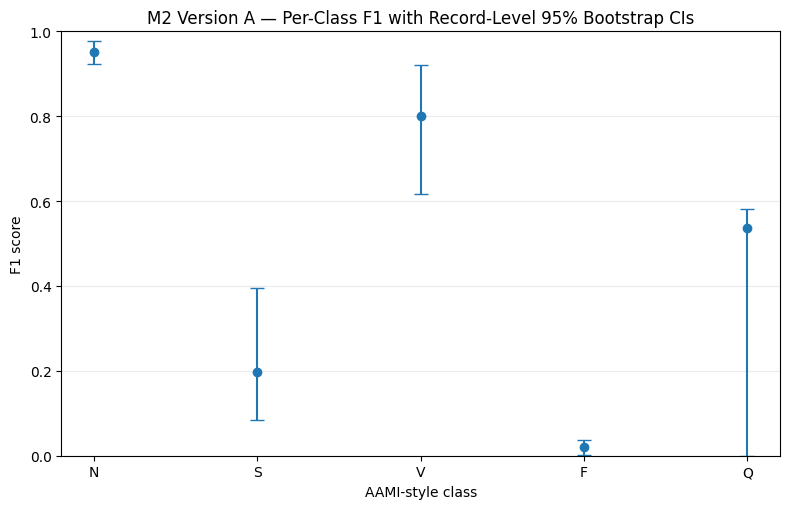

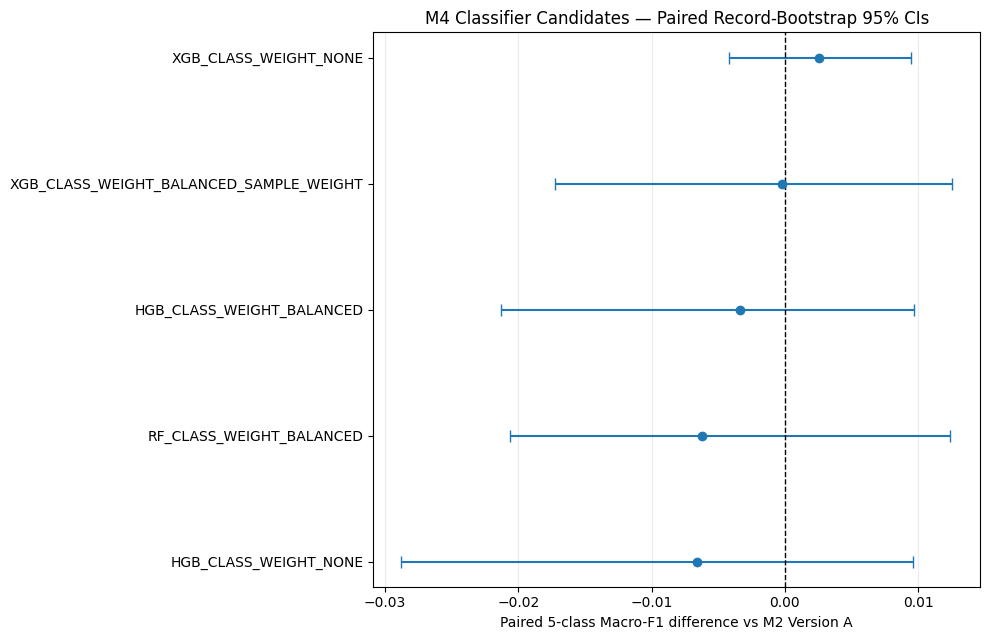

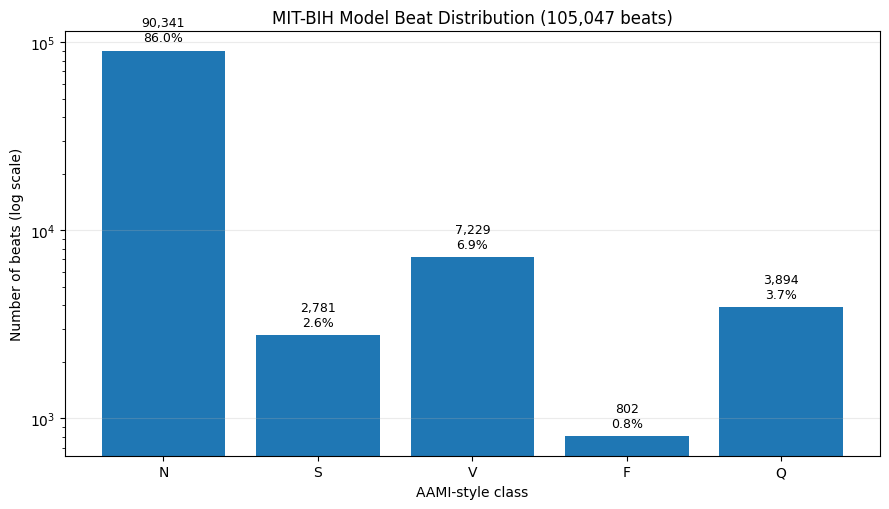

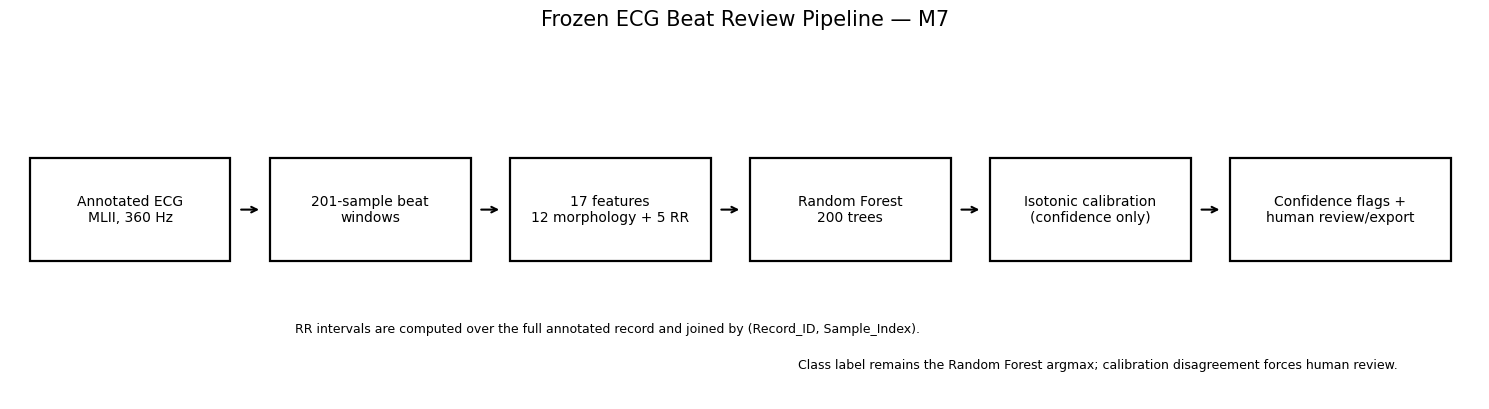

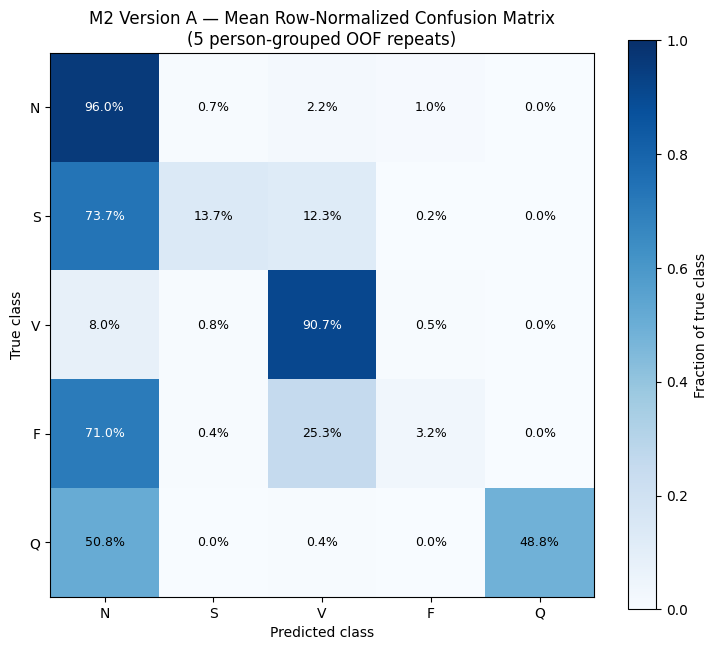

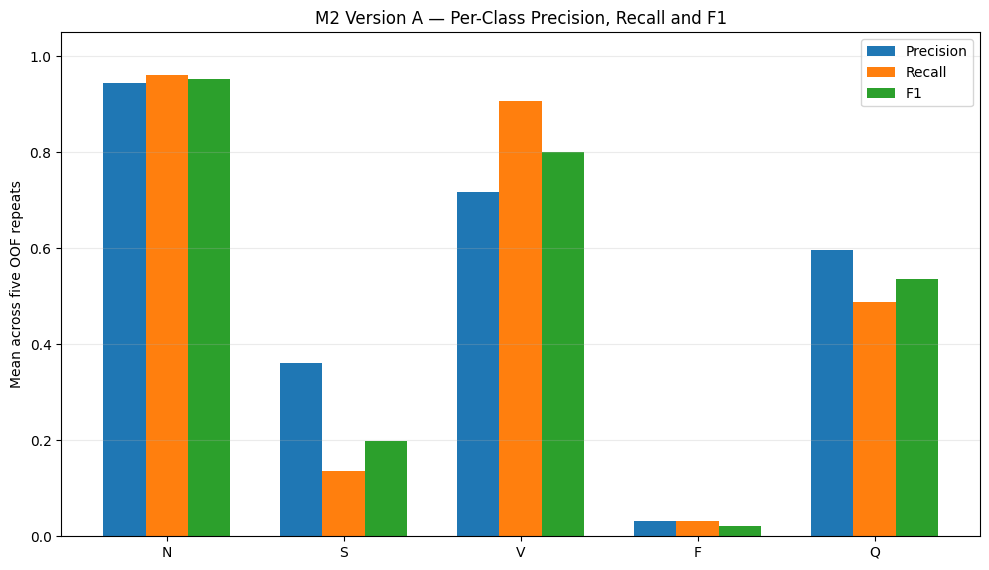

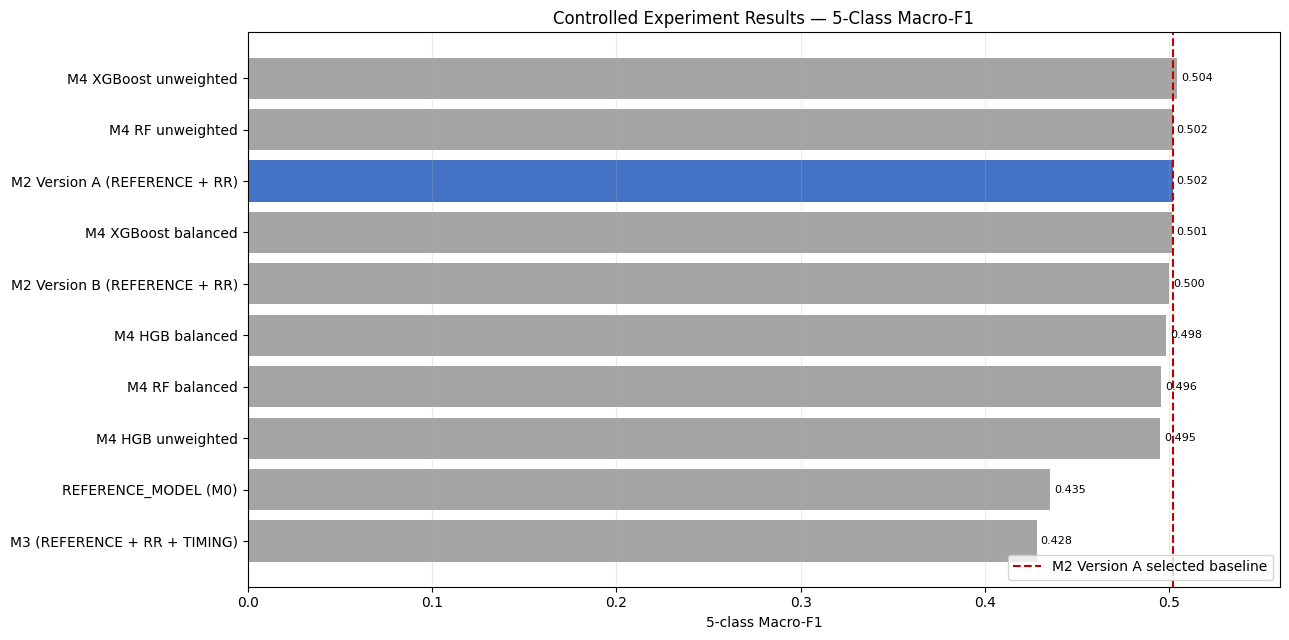

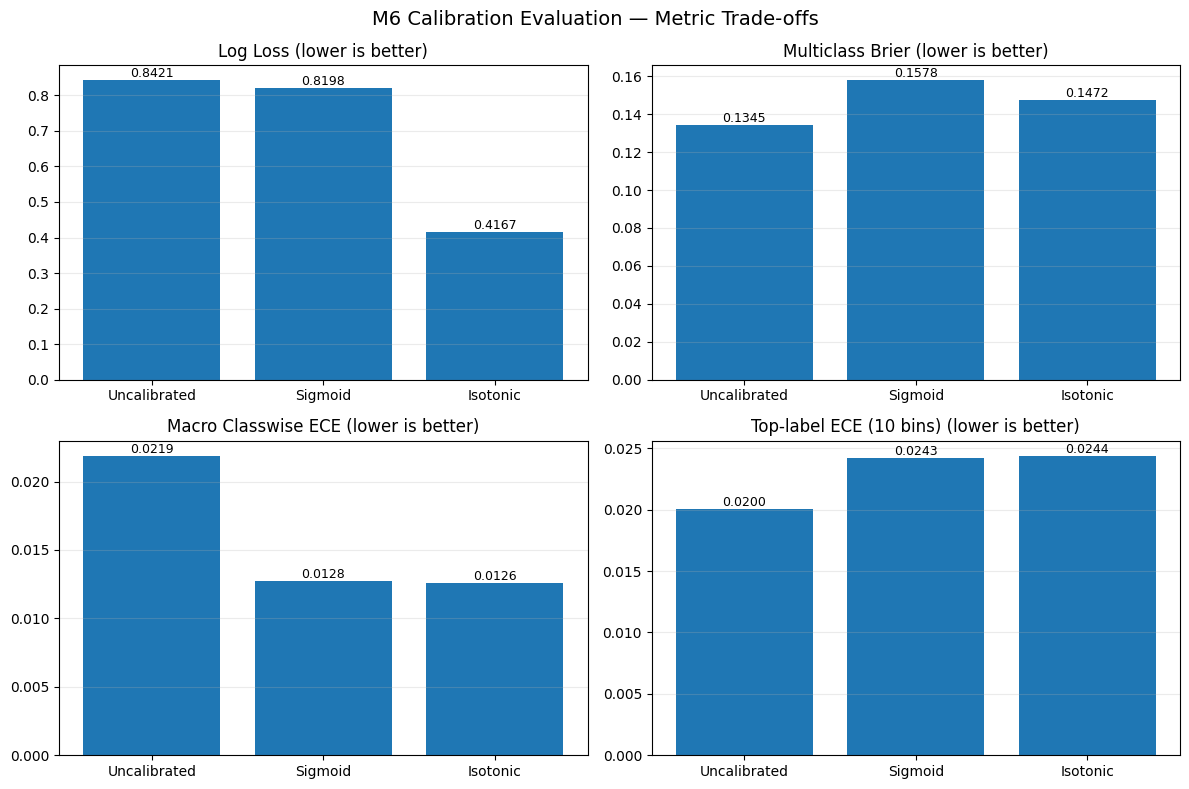

Optional M6 OOF predictions not attached: report_07_m6_reliability_curves.png will not be generated.


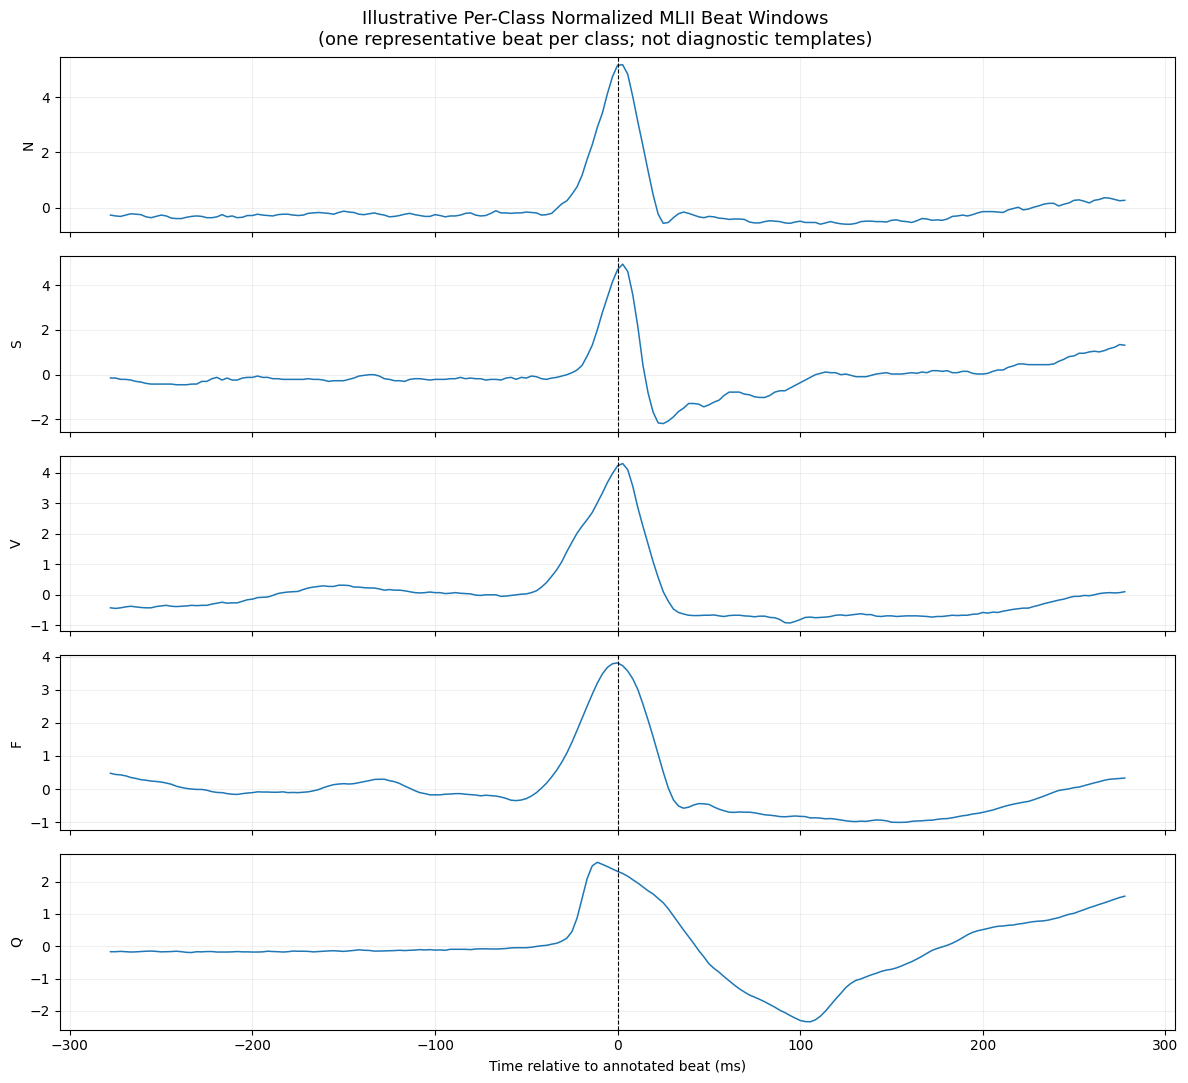

Report figures generated so far: 9


In [3]:
# Recompute M2 headline and per-class metrics from saved OOF predictions.
repeat_metric_rows = []
per_class_rows = []
confusion_matrices = []
for repeat in range(1, N_REPEATS + 1):
    part = m2_oof[m2_oof["Repeat"] == repeat].sort_values("Row_Index")
    yt = part["True_Label"].to_numpy(dtype=str)
    yp = part["Predicted_Label"].to_numpy(dtype=str)
    precision, recall, f1_values, support = precision_recall_fscore_support(yt, yp, labels=CLASS_ORDER, zero_division=0)
    four = part[part["True_Label"].isin(FOUR_CLASS_ORDER)]
    repeat_metric_rows.append({
        "Repeat": repeat,
        "Macro_F1_5_Class": f1_score(yt, yp, labels=CLASS_ORDER, average="macro", zero_division=0),
        "Macro_F1_4_Class_N_S_V_Q": f1_score(four["True_Label"], four["Predicted_Label"], labels=FOUR_CLASS_ORDER, average="macro", zero_division=0),
        "Balanced_Accuracy": balanced_accuracy_score(yt, yp),
        "Accuracy": accuracy_score(yt, yp),
    })
    for j, cls in enumerate(CLASS_ORDER):
        per_class_rows.append({"Repeat": repeat, "Class": cls, "Precision": precision[j], "Recall": recall[j], "F1": f1_values[j], "Support": support[j]})
    confusion_matrices.append(confusion_matrix(yt, yp, labels=CLASS_ORDER))

m2_repeat_metrics = pd.DataFrame(repeat_metric_rows)
m2_per_class = pd.DataFrame(per_class_rows)
m2_per_class_mean = m2_per_class.groupby("Class", sort=False)[["Precision", "Recall", "F1"]].mean().reindex(CLASS_ORDER).reset_index()
m2_headline = m2_repeat_metrics.drop(columns="Repeat").mean().to_frame().T
m2_headline.insert(0, "Experiment", "M2_VERSION_A_REFERENCE_PLUS_RR")
display(m2_repeat_metrics)
display(m2_headline)
display(m2_per_class_mean)
atomic_csv(m2_repeat_metrics, TABLE_DIR / "m7_m2_oof_metrics_by_repeat.csv", index=False)
atomic_csv(m2_headline, TABLE_DIR / "m7_m2_oof_headline_metrics.csv", index=False)
atomic_csv(m2_per_class_mean, TABLE_DIR / "m7_m2_oof_per_class_metrics_mean.csv", index=False)

# Guard against accidental change of the selected M2 result.
if abs(float(m2_headline["Macro_F1_5_Class"].iloc[0]) - 0.501716) > 1e-5:
    raise ValueError("Recomputed M2 5-class Macro-F1 does not reproduce the verified 0.501716 result.")
if abs(float(m2_headline["Macro_F1_4_Class_N_S_V_Q"].iloc[0]) - 0.625019) > 1e-5:
    raise ValueError("Recomputed M2 4-class Macro-F1 does not reproduce the verified 0.625019 result.")

# Record-level bootstrap CIs for M2 OOF Macro-F1; same 1,000 record-resampling scheme.
CLASS_INDEX = {c: i for i, c in enumerate(CLASS_ORDER)}
def macro_f1_from_confusion(M, scored_classes):
    ids = [CLASS_INDEX[c] for c in scored_classes]
    rows = M[ids, :]
    values = []
    for c in ids:
        tp = M[c, c]
        fn = M[c, :].sum() - tp
        fp = rows[:, c].sum() - tp
        denom = 2 * tp + fp + fn
        values.append(0.0 if denom == 0 else 2.0 * tp / denom)
    return float(np.mean(values))

blocks = {}
for repeat in range(1, N_REPEATS + 1):
    rp = m2_oof[m2_oof["Repeat"] == repeat]
    for rid, grp in rp.groupby("Record_ID"):
        yt = grp["True_Label"].map(CLASS_INDEX).to_numpy(dtype=int)
        yp = grp["Predicted_Label"].map(CLASS_INDEX).to_numpy(dtype=int)
        flat = yt * len(CLASS_ORDER) + yp
        blocks[(repeat, int(rid))] = np.bincount(flat, minlength=25).reshape(5, 5).astype(np.int64)
records_for_bootstrap = np.array(sorted(m2_oof["Record_ID"].unique()), dtype=int)
boot_rng = np.random.default_rng(BOOTSTRAP_SEED)
# Generate one fixed set of record-level resamples and reuse it for headline and per-class intervals.
bootstrap_record_samples = [
    boot_rng.choice(records_for_bootstrap, size=len(records_for_bootstrap), replace=True)
    for _ in range(BOOTSTRAP_SAMPLES)
]
boot_scores = {"Macro_F1_5_Class": [], "Macro_F1_4_Class_N_S_V_Q": []}
per_class_boot_scores = {(cls, metric): [] for cls in CLASS_ORDER for metric in ["Precision", "Recall", "F1"]}


def class_metrics_from_confusion(M, class_index):
    tp = float(M[class_index, class_index])
    fn = float(M[class_index, :].sum() - M[class_index, class_index])
    fp = float(M[:, class_index].sum() - M[class_index, class_index])
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1_value = (2.0 * tp / (2.0 * tp + fp + fn)) if (2.0 * tp + fp + fn) > 0 else 0.0
    return {"Precision": precision, "Recall": recall, "F1": f1_value}


for sampled_records in bootstrap_record_samples:
    repeat_scores = {k: [] for k in boot_scores}
    repeat_class_scores = {(cls, metric): [] for cls in CLASS_ORDER for metric in ["Precision", "Recall", "F1"]}
    for repeat in range(1, N_REPEATS + 1):
        M = np.zeros((5, 5), dtype=np.int64)
        for rid in sampled_records:
            M += blocks[(repeat, int(rid))]
        repeat_scores["Macro_F1_5_Class"].append(macro_f1_from_confusion(M, CLASS_ORDER))
        repeat_scores["Macro_F1_4_Class_N_S_V_Q"].append(macro_f1_from_confusion(M, FOUR_CLASS_ORDER))
        for class_index, cls in enumerate(CLASS_ORDER):
            class_values = class_metrics_from_confusion(M, class_index)
            for metric in ["Precision", "Recall", "F1"]:
                repeat_class_scores[(cls, metric)].append(class_values[metric])
    for metric in boot_scores:
        boot_scores[metric].append(float(np.mean(repeat_scores[metric])))
    for key, values in repeat_class_scores.items():
        per_class_boot_scores[key].append(float(np.mean(values)))

bootstrap_rows = []
for metric, scores in boot_scores.items():
    estimate = float(m2_headline[metric].iloc[0])
    lower, upper = np.quantile(np.asarray(scores), [0.025, 0.975])
    bootstrap_rows.append({"Experiment": "M2_VERSION_A_REFERENCE_PLUS_RR", "Metric": metric, "Point_Estimate": estimate, "CI_95_Lower": float(lower), "CI_95_Upper": float(upper), "Bootstrap_Samples": BOOTSTRAP_SAMPLES, "Resampling_Unit": "Record_ID", "Bootstrap_Seed": BOOTSTRAP_SEED})
m2_bootstrap_ci = pd.DataFrame(bootstrap_rows)
display(m2_bootstrap_ci)
atomic_csv(m2_bootstrap_ci, TABLE_DIR / "m7_m2_record_level_bootstrap_ci.csv", index=False)

# Per-class precision/recall/F1 point estimates and record-bootstrap 95% CIs.
per_class_bootstrap_rows = []
for cls in CLASS_ORDER:
    point_row = m2_per_class_mean.loc[m2_per_class_mean["Class"] == cls].iloc[0]
    for metric in ["Precision", "Recall", "F1"]:
        values = np.asarray(per_class_boot_scores[(cls, metric)], dtype=float)
        lower, upper = np.quantile(values, [0.025, 0.975])
        per_class_bootstrap_rows.append({
            "Experiment": "M2_VERSION_A_REFERENCE_PLUS_RR",
            "Class": cls,
            "Metric": metric,
            "Point_Estimate": float(point_row[metric]),
            "CI_95_Lower": float(lower),
            "CI_95_Upper": float(upper),
            "Bootstrap_Samples": BOOTSTRAP_SAMPLES,
            "Resampling_Unit": "Record_ID",
            "Bootstrap_Seed": BOOTSTRAP_SEED,
        })
m2_per_class_bootstrap_ci = pd.DataFrame(per_class_bootstrap_rows)
display(m2_per_class_bootstrap_ci)
atomic_csv(m2_per_class_bootstrap_ci, TABLE_DIR / "m7_m2_per_class_record_bootstrap_ci.csv", index=False)

# Report figure: per-class F1 with record-level bootstrap 95% intervals.
f1_ci_plot = m2_per_class_bootstrap_ci[m2_per_class_bootstrap_ci["Metric"] == "F1"].set_index("Class").loc[CLASS_ORDER]
point = f1_ci_plot["Point_Estimate"].to_numpy(dtype=float)
lo = f1_ci_plot["CI_95_Lower"].to_numpy(dtype=float)
hi = f1_ci_plot["CI_95_Upper"].to_numpy(dtype=float)
yerr = np.vstack([np.maximum(point - lo, 0), np.maximum(hi - point, 0)])
fig, ax = plt.subplots(figsize=(8, 5.2))
ax.errorbar(CLASS_ORDER, point, yerr=yerr, fmt="o", capsize=5, linewidth=1.5)
ax.set_ylim(0, 1.0)
ax.set_ylabel("F1 score")
ax.set_xlabel("AAMI-style class")
ax.set_title("M2 Version A — Per-Class F1 with Record-Level 95% Bootstrap CIs")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "report_10_per_class_f1_record_bootstrap_ci.png", dpi=300, bbox_inches="tight")
plt.show()

# Mean confusion counts over repeats (the plot below is mean row-normalized confusion).
mean_confusion_counts = np.mean(np.stack(confusion_matrices, axis=0), axis=0)
mean_confusion_counts_df = pd.DataFrame(mean_confusion_counts, index=[f"Actual_{c}" for c in CLASS_ORDER], columns=[f"Predicted_{c}" for c in CLASS_ORDER]).reset_index(names="Actual_Class")
atomic_csv(mean_confusion_counts_df, TABLE_DIR / "m7_m2_mean_confusion_counts_over_repeats.csv", index=False)

# Save the model-experiment comparison values supplied by the user.
atomic_csv(EXPERIMENT_COMPARISON, TABLE_DIR / "m7_m0_to_m6_experiment_comparison.csv", index=False)
atomic_csv(M6_CALIBRATION_SUMMARY, TABLE_DIR / "m7_m6_calibration_summary_verified_user_output.csv", index=False)

model_selection_evidence = pd.DataFrame([
    {"Candidate": "M2_VERSION_A_REFERENCE_PLUS_RR", "Comparison": "REFERENCE_MODEL", "Macro_F1_5_Class_Difference": 0.066445, "Paired_CI_95_Lower": 0.030553, "Paired_CI_95_Upper": 0.117472, "Retention_Decision": "KEEP"},
    {"Candidate": "XGB_CLASS_WEIGHT_NONE", "Comparison": "M2_VERSION_A_REFERENCE_PLUS_RR", "Macro_F1_5_Class_Difference": 0.002567, "Paired_CI_95_Lower": -0.004180, "Paired_CI_95_Upper": 0.009493, "Retention_Decision": "NO MEASURABLE IMPROVEMENT — retain M2"},
    {"Candidate": "RF_CLASS_WEIGHT_BALANCED", "Comparison": "M2_VERSION_A_REFERENCE_PLUS_RR", "Macro_F1_5_Class_Difference": -0.006197, "Paired_CI_95_Lower": -0.020607, "Paired_CI_95_Upper": 0.012368, "Retention_Decision": "NO MEASURABLE IMPROVEMENT — retain M2"},
    {"Candidate": "HGB_CLASS_WEIGHT_NONE", "Comparison": "M2_VERSION_A_REFERENCE_PLUS_RR", "Macro_F1_5_Class_Difference": -0.006621, "Paired_CI_95_Lower": -0.028791, "Paired_CI_95_Upper": 0.009619, "Retention_Decision": "NO MEASURABLE IMPROVEMENT — retain M2"},
    {"Candidate": "HGB_CLASS_WEIGHT_BALANCED", "Comparison": "M2_VERSION_A_REFERENCE_PLUS_RR", "Macro_F1_5_Class_Difference": -0.003338, "Paired_CI_95_Lower": -0.021274, "Paired_CI_95_Upper": 0.009646, "Retention_Decision": "NO MEASURABLE IMPROVEMENT — retain M2"},
    {"Candidate": "XGB_CLASS_WEIGHT_BALANCED_SAMPLE_WEIGHT", "Comparison": "M2_VERSION_A_REFERENCE_PLUS_RR", "Macro_F1_5_Class_Difference": -0.000234, "Paired_CI_95_Lower": -0.017254, "Paired_CI_95_Upper": 0.012564, "Retention_Decision": "NO MEASURABLE IMPROVEMENT — retain M2"},
])
atomic_csv(model_selection_evidence, TABLE_DIR / "m7_model_selection_paired_evidence.csv", index=False)

# Report figure: paired-retention evidence for the classifier candidates evaluated in M4.
ret_plot = model_selection_evidence[model_selection_evidence["Candidate"] != "M2_VERSION_A_REFERENCE_PLUS_RR"].copy()
ret_plot = ret_plot.sort_values("Macro_F1_5_Class_Difference")
point_delta = ret_plot["Macro_F1_5_Class_Difference"].to_numpy(dtype=float)
low_delta = ret_plot["Paired_CI_95_Lower"].to_numpy(dtype=float)
high_delta = ret_plot["Paired_CI_95_Upper"].to_numpy(dtype=float)
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.errorbar(point_delta, np.arange(len(ret_plot)), xerr=np.vstack([point_delta-low_delta, high_delta-point_delta]), fmt="o", capsize=4)
ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.set_yticks(np.arange(len(ret_plot)), ret_plot["Candidate"])
ax.set_xlabel("Paired 5-class Macro-F1 difference vs M2 Version A")
ax.set_title("M4 Classifier Candidates — Paired Record-Bootstrap 95% CIs")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "report_11_m4_paired_retention_ci.png", dpi=300, bbox_inches="tight")
plt.show()

# Figure 1 — class distribution.
fig, ax = plt.subplots(figsize=(9, 5.2))
class_counts = pd.Series(counts).reindex(CLASS_ORDER)
bars = ax.bar(CLASS_ORDER, class_counts.values)
ax.set_yscale("log")
ax.set_title("MIT-BIH Model Beat Distribution (105,047 beats)")
ax.set_xlabel("AAMI-style class")
ax.set_ylabel("Number of beats (log scale)")
for bar, val in zip(bars, class_counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, val * 1.08, f"{val:,}\n{val/EXPECTED_BEATS:.1%}", ha="center", va="bottom", fontsize=9)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "report_01_class_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

# Figure 2 — system/methodology pipeline diagram.
fig, ax = plt.subplots(figsize=(15, 4.2))
ax.set_xlim(0, 15); ax.set_ylim(0, 4); ax.axis("off")
boxes = [
    (0.2, 1.55, 2.05, 1.15, "Annotated ECG\nMLII, 360 Hz"),
    (2.65, 1.55, 2.05, 1.15, "201-sample beat\nwindows"),
    (5.1, 1.55, 2.05, 1.15, "17 features\n12 morphology + 5 RR"),
    (7.55, 1.55, 2.05, 1.15, "Random Forest\n200 trees"),
    (10.0, 1.55, 2.05, 1.15, "Isotonic calibration\n(confidence only)"),
    (12.45, 1.55, 2.25, 1.15, "Confidence flags +\nhuman review/export"),
]
for x0, y0, w0, h0, label in boxes:
    patch = plt.Rectangle((x0, y0), w0, h0, fill=False, linewidth=1.6, edgecolor="black")
    ax.add_patch(patch)
    ax.text(x0+w0/2, y0+h0/2, label, ha="center", va="center", fontsize=10)
for i in range(len(boxes)-1):
    x1 = boxes[i][0] + boxes[i][2]
    x2 = boxes[i+1][0]
    ax.annotate("", xy=(x2-0.08, 2.12), xytext=(x1+0.08, 2.12), arrowprops=dict(arrowstyle="->", lw=1.5))
ax.text(6.1, 0.75, "RR intervals are computed over the full annotated record and joined by (Record_ID, Sample_Index).", ha="center", fontsize=9)
ax.text(11.1, 0.35, "Class label remains the Random Forest argmax; calibration disagreement forces human review.", ha="center", fontsize=9)
ax.set_title("Frozen ECG Beat Review Pipeline — M7", fontsize=15, pad=12)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "report_02_model_pipeline.png", dpi=300, bbox_inches="tight")
plt.show()

# Figure 3 — mean row-normalized confusion matrix over the five OOF repeats.
normalized_cms = []
for cm in confusion_matrices:
    row_sums = cm.sum(axis=1, keepdims=True)
    normalized_cms.append(np.divide(cm, row_sums, out=np.zeros_like(cm, dtype=float), where=row_sums != 0))
mean_norm_cm = np.mean(normalized_cms, axis=0)
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(mean_norm_cm, vmin=0, vmax=1, cmap="Blues")
ax.set_xticks(range(5), CLASS_ORDER); ax.set_yticks(range(5), CLASS_ORDER)
ax.set_xlabel("Predicted class"); ax.set_ylabel("True class")
ax.set_title("M2 Version A — Mean Row-Normalized Confusion Matrix\n(5 person-grouped OOF repeats)")
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{mean_norm_cm[i,j]:.1%}", ha="center", va="center", color="white" if mean_norm_cm[i,j] > 0.55 else "black", fontsize=9)
fig.colorbar(im, ax=ax, label="Fraction of true class")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "report_03_m2_oof_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

# Figure 4 — precision, recall, F1 by class.
fig, ax = plt.subplots(figsize=(10, 5.8))
xx = np.arange(len(CLASS_ORDER)); width = 0.24
for j, metric in enumerate(["Precision", "Recall", "F1"]):
    vals = m2_per_class_mean.set_index("Class").loc[CLASS_ORDER, metric].to_numpy()
    ax.bar(xx + (j-1)*width, vals, width, label=metric)
ax.set_xticks(xx, CLASS_ORDER)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Mean across five OOF repeats")
ax.set_title("M2 Version A — Per-Class Precision, Recall and F1")
ax.legend(); ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "report_04_m2_per_class_metrics.png", dpi=300, bbox_inches="tight")
plt.show()

# Figure 5 — model experiment Macro-F1 comparison.
fig, ax = plt.subplots(figsize=(13, 6.5))
comp = EXPERIMENT_COMPARISON.copy()
plot_comp = comp[~comp["Experiment"].str.startswith("M6")].sort_values("Macro_F1_5_Class", ascending=True)
colors = ["#4472C4" if s == "Selected model" else "#A5A5A5" for s in plot_comp["Status"]]
bars = ax.barh(plot_comp["Experiment"], plot_comp["Macro_F1_5_Class"], color=colors)
ax.axvline(0.501716, color="#C00000", linestyle="--", linewidth=1.5, label="M2 Version A selected baseline")
ax.set_xlim(0, max(plot_comp["Macro_F1_5_Class"].max()+0.04, 0.56))
ax.set_xlabel("5-class Macro-F1")
ax.set_title("Controlled Experiment Results — 5-Class Macro-F1")
ax.legend(loc="lower right"); ax.grid(axis="x", alpha=0.25)
for bar, val in zip(bars, plot_comp["Macro_F1_5_Class"]):
    ax.text(val+0.002, bar.get_y()+bar.get_height()/2, f"{val:.3f}", va="center", fontsize=8)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "report_05_experiment_comparison_macro_f1.png", dpi=300, bbox_inches="tight")
plt.show()

# Figure 6 — M6 calibration metric trade-offs (lower is better).
cal_metrics = [
    ("Log_Loss", "Log Loss"),
    ("Brier_Score", "Multiclass Brier"),
    ("Macro_Class_ECE", "Macro Classwise ECE"),
    ("Top_Label_ECE_10_Bins", "Top-label ECE (10 bins)"),
]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (metric, title) in zip(axes.ravel(), cal_metrics):
    vals = M6_CALIBRATION_SUMMARY.set_index("Experiment").loc[["M2_UNCALIBRATED", "M6_SIGMOID", "M6_ISOTONIC"], metric]
    ax.bar(["Uncalibrated", "Sigmoid", "Isotonic"], vals.values)
    ax.set_title(title + " (lower is better)")
    ax.grid(axis="y", alpha=0.25)
    for i, v in enumerate(vals.values): ax.text(i, v, f"{v:.4f}", ha="center", va="bottom", fontsize=9)
fig.suptitle("M6 Calibration Evaluation — Metric Trade-offs", fontsize=14)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "report_06_m6_calibration_metric_tradeoffs.png", dpi=300, bbox_inches="tight")
plt.show()

# Optional Figure 7 — reliability curves from M6's saved nested OOF predictions.
def reliability_points_from_oof(frame, experiment):
    out = []
    for rep in range(1, N_REPEATS+1):
        part = frame[frame["Repeat"] == rep]
        probs = part[PROB_COLS].to_numpy(dtype=float)
        labels = part["True_Label"].to_numpy(dtype=str)
        for j, cls in enumerate(CLASS_ORDER):
            p = probs[:, j]; truth_bin = (labels == cls).astype(float)
            bin_ids = np.minimum((np.clip(p, 0, 1) * 10).astype(int), 9)
            for b in range(10):
                mask = bin_ids == b
                if mask.any():
                    out.append({"Experiment": experiment, "Repeat": rep, "Class": cls, "Bin": b,
                                "Mean_Predicted_Probability": float(p[mask].mean()),
                                "Observed_Frequency": float(truth_bin[mask].mean()), "Count": int(mask.sum())})
    return pd.DataFrame(out)

reliability_frames = []
if m6_iso_oof is not None:
    reliability_frames.append(reliability_points_from_oof(m6_iso_oof, "M6_ISOTONIC"))
if m6_sig_oof is not None:
    reliability_frames.append(reliability_points_from_oof(m6_sig_oof, "M6_SIGMOID"))
if reliability_frames:
    rel = pd.concat(reliability_frames, ignore_index=True)
    rel_summary = rel.groupby(["Experiment", "Class", "Bin"], sort=False).agg(
        Mean_Predicted_Probability=("Mean_Predicted_Probability", "mean"),
        Observed_Frequency=("Observed_Frequency", "mean"),
        Mean_Count=("Count", "mean"),
    ).reset_index()
    fig, axes = plt.subplots(2, 3, figsize=(15, 9)); axes = axes.ravel()
    for j, cls in enumerate(CLASS_ORDER):
        ax = axes[j]
        ax.plot([0,1], [0,1], "k--", linewidth=1, label="Perfect calibration")
        for exp_name in ["M6_SIGMOID", "M6_ISOTONIC"]:
            sub = rel_summary[(rel_summary["Experiment"] == exp_name) & (rel_summary["Class"] == cls)]
            if len(sub): ax.plot(sub["Mean_Predicted_Probability"], sub["Observed_Frequency"], marker="o", label=exp_name)
        ax.set_title(f"Class {cls}"); ax.set_xlabel("Mean predicted probability"); ax.set_ylabel("Observed frequency")
        ax.set_xlim(0,1); ax.set_ylim(0,1); ax.grid(alpha=0.25); ax.legend(fontsize=7)
    axes[5].axis("off")
    fig.suptitle("M6 Nested OOF Per-Class Reliability Curves", fontsize=14)
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / "report_07_m6_reliability_curves.png", dpi=300, bbox_inches="tight")
    plt.show()
    atomic_csv(rel_summary, TABLE_DIR / "m7_m6_reliability_curve_summary_recomputed.csv", index=False)
else:
    print("Optional M6 OOF predictions not attached: report_07_m6_reliability_curves.png will not be generated.")

# Figure 8 — illustrative normalized beat examples; not a clinical template or a typical-beat claim.
fig, axes = plt.subplots(5, 1, figsize=(12, 11), sharex=True)
time_ms = (np.arange(201) - 100) / SAMPLE_RATE_HZ * 1000.0
rng_examples = np.random.default_rng(SEED)
for ax, cls in zip(axes, CLASS_ORDER):
    idx = np.flatnonzero(y == cls)
    if len(idx) > 500: idx = rng_examples.choice(idx, size=500, replace=False)
    class_waves = normalized_wave[idx]
    med = np.median(class_waves, axis=0)
    distances = np.square(class_waves - med).mean(axis=1)
    chosen = class_waves[int(np.argmin(distances))]
    ax.plot(time_ms, chosen, linewidth=1.1)
    ax.axvline(0, color="black", linestyle="--", linewidth=0.8)
    ax.set_ylabel(cls); ax.grid(alpha=0.2)
axes[-1].set_xlabel("Time relative to annotated beat (ms)")
fig.suptitle("Illustrative Per-Class Normalized MLII Beat Windows\n(one representative beat per class; not diagnostic templates)", fontsize=13)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "report_08_illustrative_beat_waveforms.png", dpi=300, bbox_inches="tight")
plt.show()

print("Report figures generated so far:", len(list(FIGURE_DIR.glob("*.png"))))

## 3. Fit the final isotonic calibrator and confidence-review thresholds

For the final deployment artifact, average each beat's saved M2 OOF probability over the five repeats. Every contributing prediction is out-of-fold for that beat's person. Fit the final one-vs-rest isotonic maps on this cross-fitted probability table, then train the final Random Forest on all development rows.

The application policy preserves the Random Forest's class label. The calibrated probability attached to that label determines confidence. If the calibrated top class differs from the Random Forest label, mark the beat for mandatory human review. This avoids silently replacing the selected M2 label when calibration changes class ranking.

In [4]:
# Average repeated OOF probabilities to one cross-fitted probability vector per beat.
oof_mean = m2_oof.groupby("Row_Index")[PROB_COLS].mean().reindex(row_ids)
if oof_mean.isna().any().any() or len(oof_mean) != EXPECTED_BEATS:
    raise ValueError("Could not construct one mean OOF probability vector per beat.")
P_OOF_MEAN = oof_mean.to_numpy(dtype=np.float64)
validate_probability_matrix(P_OOF_MEAN, "Mean repeated M2 OOF probabilities")


def fit_final_ovr_isotonic(probabilities, labels):
    probabilities = np.asarray(probabilities, dtype=float)
    labels = np.asarray(labels, dtype=str)
    calibrators = []
    audit = []
    for j, cls in enumerate(CLASS_ORDER):
        binary = (labels == cls).astype(int)
        if binary.sum() == 0 or binary.sum() == len(binary):
            raise ValueError(f"Cannot fit one-vs-rest calibrator for class {cls}: no binary variation.")
        cal = IsotonicRegression(y_min=0.0, y_max=1.0, out_of_bounds="clip")
        cal.fit(np.clip(probabilities[:, j], 1e-7, 1-1e-7), binary)
        calibrators.append(cal)
        audit.append({"Class": cls, "Method": "isotonic", "Positive_Count": int(binary.sum()), "Negative_Count": int(len(binary)-binary.sum()), "Fit_Status": "FITTED"})
    return calibrators, pd.DataFrame(audit)


def apply_final_calibration(raw_probabilities, calibrators):
    raw = np.asarray(raw_probabilities, dtype=float)
    validate_probability_matrix(raw, "Raw probabilities before isotonic calibration")
    calibrated = np.zeros_like(raw, dtype=float)
    for j, cal in enumerate(calibrators):
        calibrated[:, j] = cal.predict(np.clip(raw[:, j], 1e-7, 1-1e-7))
    calibrated = np.clip(calibrated, 0.0, 1.0)
    sums = calibrated.sum(axis=1, keepdims=True)
    zero_rows = sums[:, 0] <= 1e-15
    if zero_rows.any():
        calibrated[zero_rows] = 1.0 / len(CLASS_ORDER)
        sums = calibrated.sum(axis=1, keepdims=True)
    calibrated /= sums
    validate_probability_matrix(calibrated, "Isotonic calibrated probabilities")
    return calibrated.astype(np.float32)


final_calibrators, calibrator_audit = fit_final_ovr_isotonic(P_OOF_MEAN, y)
P_OOF_CALIBRATED = apply_final_calibration(P_OOF_MEAN, final_calibrators)
raw_oof_labels = np.asarray(CLASS_ORDER)[np.argmax(P_OOF_MEAN, axis=1)]
calibrated_top_oof = np.asarray(CLASS_ORDER)[np.argmax(P_OOF_CALIBRATED, axis=1)]
raw_label_indices = np.argmax(P_OOF_MEAN, axis=1)
calibrated_probability_for_raw_label = P_OOF_CALIBRATED[np.arange(EXPECTED_BEATS), raw_label_indices]
calibration_disagreement_oof = raw_oof_labels != calibrated_top_oof

# Per-class thresholds are fitted on cross-fitted training probabilities. They apply to the
# calibrated probability of the unchanged Random Forest label, not to calibrated argmax.
threshold_rows = []
final_thresholds = {}
for cls in CLASS_ORDER:
    cls_mask = raw_oof_labels == cls
    selected = 1.01
    selected_precision = np.nan
    selected_count = 0
    status = "NO_THRESHOLD_MET_TARGET_ALL_FLAGGED"
    if cls == "F":
        status = "ALWAYS_FLAG_NOT_SUPPORTED_EXPERIMENTAL"
    else:
        for threshold in THRESHOLD_GRID:
            keep = cls_mask & (calibrated_probability_for_raw_label >= threshold)
            support = int(keep.sum())
            if support < MIN_THRESHOLD_SUPPORT:
                continue
            precision_at_threshold = float((raw_oof_labels[keep] == y[keep]).mean())
            if precision_at_threshold >= TARGET_HIGH_CONFIDENCE_PRECISION:
                selected = float(threshold)
                selected_precision = precision_at_threshold
                selected_count = support
                status = "THRESHOLD_SELECTED"
                break
    final_thresholds[cls] = float(selected)
    threshold_rows.append({
        "Class": cls,
        "Threshold": float(selected),
        "Status": status,
        "OOF_Raw_Predicted_Class_Count": int(cls_mask.sum()),
        "OOF_Unflagged_Count_At_Threshold": selected_count,
        "OOF_Unflagged_Precision": selected_precision,
        "Target_Precision": TARGET_HIGH_CONFIDENCE_PRECISION,
        "Minimum_Support": MIN_THRESHOLD_SUPPORT,
        "Calibration_Disagreement_Rows_Also_Require_Review": True,
    })
final_threshold_table = pd.DataFrame(threshold_rows)
display(calibrator_audit)
display(final_threshold_table)
atomic_csv(calibrator_audit, TABLE_DIR / "m7_final_isotonic_calibrator_fit_audit.csv", index=False)
atomic_csv(final_threshold_table, TABLE_DIR / "m7_final_confidence_thresholds.csv", index=False)

,Class,Method,Positive_Count,Negative_Count,Fit_Status
0,N,isotonic,90341,14706,FITTED
1,S,isotonic,2781,102266,FITTED
2,V,isotonic,7229,97818,FITTED
3,F,isotonic,802,104245,FITTED
4,Q,isotonic,3894,101153,FITTED


,Class,Threshold,Status,OOF_Raw_Predicted_Class_Count,OOF_Unflagged_Count_At_Threshold,OOF_Unflagged_Precision,Target_Precision,Minimum_Support,Calibration_Disagreement_Rows_Also_Require_Review
0,N,0.05,THRESHOLD_SELECTED,92588,92588,0.945641,0.8,30,True
1,S,0.66,THRESHOLD_SELECTED,890,74,0.837838,0.8,30,True
2,V,0.33,THRESHOLD_SELECTED,9234,7672,0.813347,0.8,30,True
3,F,1.01,ALWAYS_FLAG_NOT_SUPPORTED_EXPERIMENTAL,222,0,NaN,0.8,30,True
4,Q,0.05,THRESHOLD_SELECTED,2113,2113,0.999053,0.8,30,True


## 4. Train and save ONE final pipeline bundle

The final estimator is fitted on all 105,047 development beats. Training-set predictions are not used as evaluation results. The independent-looking performance numbers in the report remain the saved out-of-fold results.

Fitting final Random Forest on all development rows: (105047, 17)
FINAL PIPELINE SAVED: /kaggle/working/ECG_Project/09_M7_FINAL_MODEL_FREEZE/m7_final_ecg_pipeline.joblib


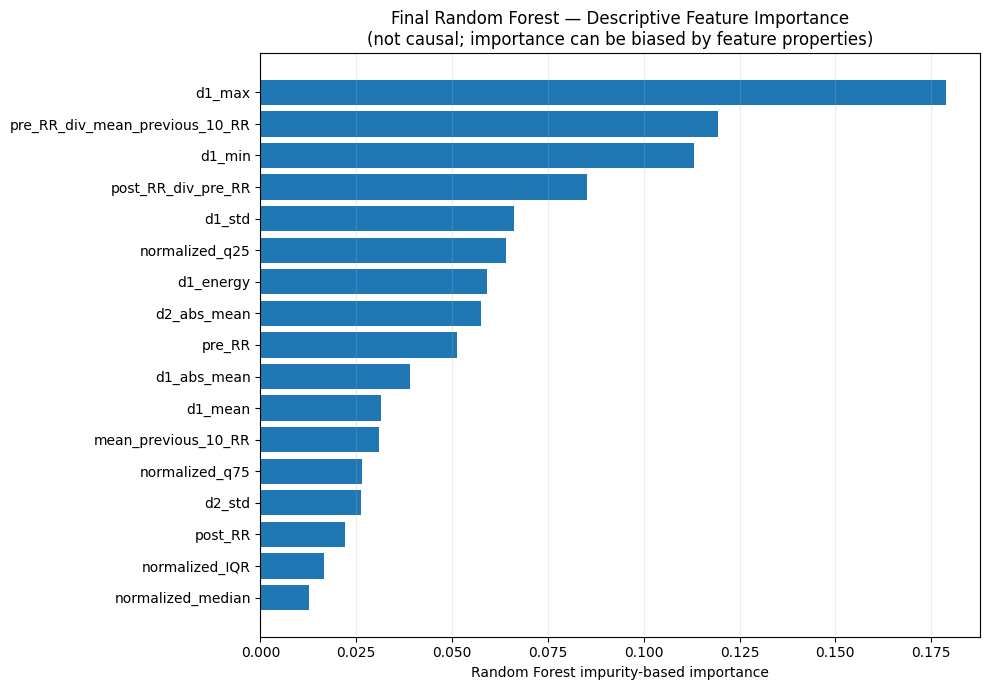

,Check,Result
0,All_pre_freeze_validation_checks_passed,PASS
1,Final_RF_fitted_on_all_105047_development_beats,PASS
2,Final_RF_contains_all_five_classes,PASS
3,Final_isotonic_calibrators_fitted_for_all_classes,PASS
4,Final_confidence_thresholds_defined_for_all_cl...,PASS
5,Final_pipeline_bundle_saved,PASS
6,Reusable_inference_module_saved,PASS
7,Model_card_and_manifest_saved,PASS
8,Application_integration_readme_saved,PASS
9,Pinned_dependency_versions_saved,PASS


Final model reload and probability smoke test — PASS
M7 FINAL MODEL FREEZE — COMPLETE
Output folder: /kaggle/working/ECG_Project/09_M7_FINAL_MODEL_FREEZE
Download archive: /kaggle/working/ECG_Project/M7_Final_Model_and_Report_Artifacts.zip


In [5]:
if RUN_M7_FREEZE:
    final_model = RandomForestClassifier(
        n_estimators=TREES,
        max_features=MAX_FEATURES,
        min_samples_split=2,
        min_samples_leaf=1,
        random_state=SEED,
        n_jobs=-1,
        class_weight=None,
    )
    print("Fitting final Random Forest on all development rows:", X.shape)
    final_model.fit(X, y)
    if set(final_model.classes_.astype(str)) != set(CLASS_ORDER):
        raise ValueError(f"Final model classes differ from expected: {final_model.classes_}")

    pipeline_bundle = {
        "artifact_name": "ECG_Beat_Review_Assistant_M7_Final_Pipeline",
        "artifact_version": "1.0.0",
        "base_model_name": "M2 Version A — unweighted RandomForestClassifier",
        "estimator": final_model,
        "class_order": CLASS_ORDER,
        "feature_names": FEATURE_NAMES,
        "feature_count": 17,
        "reference_feature_names": REFERENCE_FEATURE_NAMES,
        "rr_feature_names": RR_FEATURES,
        "normalization": "per-beat MLII z-normalization: subtract row mean, divide by row std; zero std replaced with 1",
        "feature_builder_module": "m7_inference.py",
        "feature_contract": "build_reference_features(201-sample MLII window) + five RR_FEATURES aligned by (Record_ID, Sample_Index); see rr_policy",
        "random_forest_parameters": {"n_estimators": TREES, "max_features": MAX_FEATURES, "min_samples_split": 2, "min_samples_leaf": 1, "random_state": SEED, "class_weight": None, "n_jobs": -1},
        "calibration_method": FINAL_CALIBRATION_METHOD,
        "calibrators_one_vs_rest": final_calibrators,
        "calibration_fit_source": "mean of five repeated saved M2 Version A OOF probability vectors per beat; each vector was generated with that beat's person held out",
        "label_policy": "retain the uncalibrated Random Forest argmax as the predicted class; attach isotonic calibrated probability for that class; calibration top-class disagreement triggers mandatory human review",
        "confidence_thresholds": final_thresholds,
        "confidence_policy": {"target_predicted_class_precision": TARGET_HIGH_CONFIDENCE_PRECISION, "minimum_support": MIN_THRESHOLD_SUPPORT, "threshold_grid": [0.05, 1.00, 0.01], "class_F": "always flag as not supported / experimental", "calibration_disagreement": "always flag for human review", "clinical_threshold": False},
        "rr_policy": {"sampling_rate_hz": 360.0, "interval_source": "full annotated beat sequence per record", "mask_symbols": ["~", "|", "!", "[", "]"], "keep_symbols": ["x", "+", '"'], "first_pre_RR": "NaN", "last_post_RR": "NaN", "mean_previous_10_RR": "mean of valid intervals among preceding 10, requiring at least 5", "clipping": "none", "imputation": "none; native Random Forest NaN handling"},
        "dataset": {"name": "MIT-BIH Arrhythmia Database (Kaggle copy)", "valid_beats": EXPECTED_BEATS, "records": EXPECTED_RECORDS, "people": EXPECTED_PEOPLE, "class_counts": counts, "sampling_rate_hz": SAMPLE_RATE_HZ, "lead": "MLII", "window_samples": 201},
        "split_fingerprint": computed_fp,
        "training_scope": "all 45 development people; no separately recorded demo-person holdout",
        "python_version": sys.version,
        "numpy_version": np.__version__,
        "pandas_version": pd.__version__,
        "scikit_learn_version": sklearn.__version__,
        "joblib_version": joblib.__version__,
        "matplotlib_version": plt.matplotlib.__version__,
        "pinned_python_version": platform.python_version(),
    }
    model_path = OUTPUT_DIR / "m7_final_ecg_pipeline.joblib"
    joblib.dump(pipeline_bundle, model_path, compress=3)
    print("FINAL PIPELINE SAVED:", model_path)

    requirements_text = "\n".join([
        f"numpy=={np.__version__}",
        f"pandas=={pd.__version__}",
        f"scikit-learn=={sklearn.__version__}",
        f"joblib=={joblib.__version__}",
        f"matplotlib=={plt.matplotlib.__version__}",
    ]) + "\n"
    (OUTPUT_DIR / "m7_requirements_frozen.txt").write_text(requirements_text, encoding="utf-8")
    (OUTPUT_DIR / "m7_python_version.txt").write_text(platform.python_version() + "\n", encoding="utf-8")

    # Built-in feature importance is descriptive only, not causal or patient-level explanation.
    feature_importance = pd.DataFrame({"Feature": FEATURE_NAMES, "Impurity_Importance": final_model.feature_importances_}).sort_values("Impurity_Importance", ascending=False)
    atomic_csv(feature_importance, TABLE_DIR / "m7_final_random_forest_feature_importance.csv", index=False)
    fig, ax = plt.subplots(figsize=(10, 7))
    top = feature_importance.head(17).sort_values("Impurity_Importance", ascending=True)
    ax.barh(top["Feature"], top["Impurity_Importance"])
    ax.set_xlabel("Random Forest impurity-based importance")
    ax.set_title("Final Random Forest — Descriptive Feature Importance\n(not causal; importance can be biased by feature properties)")
    ax.grid(axis="x", alpha=0.25)
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / "report_09_final_rf_feature_importance.png", dpi=300, bbox_inches="tight")
    plt.show()

    # Reusable pure inference module: same reference feature construction and M2 RR logic.
    inference_module = r'''"""M7 inference helpers for ECG Beat Review and Annotation Assistant.

The caller must first parse the source record and construct centred 201-sample MLII
windows in beat order. RR features must be computed from the full annotation sequence
for each record, then aligned to model beats by (Record_ID, Sample_Index).
"""
from pathlib import Path
import joblib
import numpy as np
import pandas as pd

CLASS_ORDER = ["N", "S", "V", "F", "Q"]
RR_FEATURES = ["pre_RR", "post_RR", "mean_previous_10_RR", "pre_RR_div_mean_previous_10_RR", "post_RR_div_pre_RR"]
MASK_SYMBOLS = ("~", "|", "!", "[", "]")
SAMPLE_RATE_HZ = 360.0


def interval_flags(beat_samples, marker_samples, marker_symbols, mask_symbols=MASK_SYMBOLS):
    """True for interval j (beat j-1 -> j) containing a mask marker strictly inside."""
    s = np.asarray(beat_samples, dtype=np.int64)
    n = len(s)
    flags = np.zeros(n, dtype=bool)
    if n < 2 or len(marker_samples) == 0:
        return flags
    m_pos = np.asarray(marker_samples, dtype=np.int64)
    m_sym = np.asarray(marker_symbols)
    order = np.argsort(m_pos, kind="stable")
    m_pos, m_sym = m_pos[order], m_sym[order]
    is_mask = np.isin(m_sym, list(mask_symbols)).astype(np.int64)
    cs = np.concatenate([[0], np.cumsum(is_mask)])
    left = np.searchsorted(m_pos, s[:-1], side="right")
    right = np.searchsorted(m_pos, s[1:], side="left")
    flags[1:] = (cs[right] - cs[left]) > 0
    return flags


def compute_rr_features(beat_samples, flagged=None, fs=SAMPLE_RATE_HZ, window=10, min_valid=5):
    """One record's sorted beat sample positions -> five M2 Version A RR features."""
    s = np.asarray(beat_samples, dtype=np.int64)
    if len(s) < 2:
        raise ValueError("Need at least two beats in a record.")
    gaps = np.diff(s)
    if np.any(gaps <= 0):
        raise ValueError("Beat positions must be strictly increasing.")
    val = np.full(len(s), np.nan, dtype=float)
    val[1:] = gaps / fs
    if flagged is not None:
        flagged = np.asarray(flagged, dtype=bool)
        if flagged.shape != val.shape:
            raise ValueError("flagged must have one boolean per beat/interval.")
        val[flagged] = np.nan
    pre = val.copy()
    post = np.full(len(s), np.nan, dtype=float)
    post[:-1] = val[1:]
    mean_prev = pd.Series(pre).shift(1).rolling(window=window, min_periods=min_valid).mean().to_numpy()
    with np.errstate(divide="ignore", invalid="ignore"):
        ratio_pre = np.where(np.isfinite(pre) & np.isfinite(mean_prev) & (mean_prev > 0), pre / mean_prev, np.nan)
        ratio_post = np.where(np.isfinite(post) & np.isfinite(pre) & (pre > 0), post / pre, np.nan)
    return np.column_stack([pre, post, mean_prev, ratio_pre, ratio_post]).astype(np.float32)


def build_reference_features(mlii_windows):
    """201-sample raw MLII beat windows -> exact 12 M2 reference features."""
    w = np.asarray(mlii_windows, dtype=np.float32)
    if w.ndim != 2 or w.shape[1] != 201:
        raise ValueError(f"Expected mlii_windows shape (n, 201); got {w.shape}.")
    means = w.mean(axis=1, keepdims=True)
    stds = w.std(axis=1, keepdims=True)
    stds[stds == 0] = 1.0
    z = (w - means) / stds
    d1 = np.diff(z, axis=1)
    d2 = np.diff(z, n=2, axis=1)
    q25, q50, q75 = np.percentile(z, [25, 50, 75], axis=1)
    return np.column_stack([
        d1.mean(axis=1), d1.std(axis=1), d1.max(axis=1), d1.min(axis=1),
        np.abs(d1).mean(axis=1), np.square(d1).mean(axis=1),
        d2.std(axis=1), np.abs(d2).mean(axis=1), q50, q75-q25, q25, q75,
    ]).astype(np.float32)


def build_feature_matrix(mlii_windows, rr_feature_matrix):
    """Build the 17-feature M2 Version A matrix from MLII windows and aligned RR rows."""
    ref = build_reference_features(mlii_windows)
    rr = np.asarray(rr_feature_matrix, dtype=np.float32)
    if rr.ndim != 2 or rr.shape != (len(ref), 5):
        raise ValueError(f"Expected RR feature matrix {(len(ref), 5)}; got {rr.shape}.")
    if np.isinf(rr).any():
        raise ValueError("RR feature matrix contains infinite values.")
    return np.column_stack([ref, rr]).astype(np.float32)


def load_pipeline(path):
    bundle = joblib.load(Path(path))
    if bundle.get("artifact_name") != "ECG_Beat_Review_Assistant_M7_Final_Pipeline":
        raise ValueError("This file is not the expected M7 ECG pipeline bundle.")
    return bundle


def apply_calibration(raw_probabilities, calibrators):
    raw = np.asarray(raw_probabilities, dtype=float)
    out = np.zeros_like(raw, dtype=float)
    for j, cal in enumerate(calibrators):
        out[:, j] = cal.predict(np.clip(raw[:, j], 1e-7, 1-1e-7))
    out = np.clip(out, 0.0, 1.0)
    sums = out.sum(axis=1, keepdims=True)
    zero = sums[:, 0] <= 1e-15
    if zero.any():
        out[zero] = 1.0 / len(CLASS_ORDER)
        sums = out.sum(axis=1, keepdims=True)
    return (out / sums).astype(np.float32)


def predict_from_feature_matrix(bundle, X):
    """Return RF labels, calibrated class probabilities, confidence, and review flags."""
    X = np.asarray(X, dtype=np.float32)
    if X.ndim != 2 or X.shape[1] != bundle["feature_count"]:
        raise ValueError(f"Expected a 17-column feature matrix; got {X.shape}.")
    if np.isinf(X).any():
        raise ValueError("Feature matrix contains infinite values.")
    model = bundle["estimator"]
    raw_model_prob = model.predict_proba(X)
    raw_prob = np.zeros((len(X), len(CLASS_ORDER)), dtype=np.float32)
    for j, cls in enumerate(model.classes_):
        raw_prob[:, CLASS_ORDER.index(str(cls))] = raw_model_prob[:, j]
    calibrated = apply_calibration(raw_prob, bundle["calibrators_one_vs_rest"])
    raw_idx = raw_prob.argmax(axis=1)
    cal_idx = calibrated.argmax(axis=1)
    raw_label = np.asarray(CLASS_ORDER)[raw_idx]
    cal_top = np.asarray(CLASS_ORDER)[cal_idx]
    confidence = calibrated[np.arange(len(X)), raw_idx]  # calibrated probability of RF-selected class
    threshold_map = bundle["confidence_thresholds"]
    threshold = np.asarray([threshold_map[c] for c in raw_label], dtype=float)
    disagreement = raw_idx != cal_idx
    is_f = raw_label == "F"
    low = (confidence < threshold) | disagreement | is_f
    reasons = []
    for i in range(len(X)):
        parts = []
        if is_f[i]: parts.append("F_NOT_SUPPORTED_EXPERIMENTAL")
        if disagreement[i]: parts.append("CALIBRATION_TOP_CLASS_DISAGREEMENT")
        if confidence[i] < threshold[i]: parts.append("BELOW_CLASS_CONFIDENCE_THRESHOLD")
        reasons.append(";".join(parts) if parts else "NONE")
    result = pd.DataFrame({
        "Predicted_Label": raw_label,
        "Calibrated_Top_Class": cal_top,
        "Calibration_Disagrees_With_RF_Label": disagreement,
        "Calibrated_Probability_For_RF_Label": confidence,
        "Confidence_Threshold": threshold,
        "Low_Confidence_Flag": low,
        "Review_Reason": reasons,
    })
    for j, cls in enumerate(CLASS_ORDER):
        result[f"Raw_Prob_{cls}"] = raw_prob[:, j]
        result[f"Calibrated_Prob_{cls}"] = calibrated[:, j]
    return result


def predict_from_windows(bundle, mlii_windows, rr_feature_matrix):
    X = build_feature_matrix(mlii_windows, rr_feature_matrix)
    return predict_from_feature_matrix(bundle, X)
'''
    inference_path = OUTPUT_DIR / "m7_inference.py"
    inference_path.write_text(inference_module, encoding="utf-8")

    # Freeze manifest, model card and decision note.
    manifest = {
        "phase": "M7 — FINAL MODEL FREEZE",
        "final_pipeline_file": model_path.name,
        "inference_module_file": inference_path.name,
        "base_model": "M2 Version A — unweighted RandomForestClassifier",
        "features": FEATURE_NAMES,
        "feature_count": 17,
        "class_order": CLASS_ORDER,
        "training_beats": EXPECTED_BEATS,
        "training_records": EXPECTED_RECORDS,
        "training_people": EXPECTED_PEOPLE,
        "class_counts": counts,
        "split_fingerprint": computed_fp,
        "splits_regenerated": False,
        "demo_person_holdout_available": False,
        "demo_person_evaluation": "NOT AVAILABLE: all 45 people are in the saved M0 development/CV split set; no separately designated demo holdout list was supplied.",
        "random_forest": pipeline_bundle["random_forest_parameters"],
        "calibration_method": FINAL_CALIBRATION_METHOD,
        "calibration_fit_source": pipeline_bundle["calibration_fit_source"],
        "calibration_tradeoff": "Isotonic has best reported log loss and macro classwise ECE; its multiclass Brier and top-label ECE are worse than uncalibrated. M6 calibrated-argmax Macro-F1 is 0.405207. The deployed app policy keeps RF labels and uses calibrated probabilities for confidence/review; calibration disagreement is mandatory review.",
        "confidence_policy": pipeline_bundle["confidence_policy"],
        "rr_policy": pipeline_bundle["rr_policy"],
        "evaluation_source": "Saved M2 Version A OOF predictions across 5 person-grouped repeats; M6 nested OOF calibration evaluation where available.",
        "not_a_diagnostic_tool": True,
        "software_versions": {"python": sys.version, "numpy": np.__version__, "pandas": pd.__version__, "scikit_learn": sklearn.__version__, "joblib": joblib.__version__},
    }
    (OUTPUT_DIR / "m7_model_manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")

    model_card = f'''# ECG Beat Review and Annotation Assistant — Model Card

## Intended use
This model supports an educational ECG viewing aid and a human-led beat annotation/review workflow. It pre-labels annotated beats and prioritizes uncertain predictions for human review. A human must review and decide the final annotation.

**This is not a diagnostic tool. It must not be used for diagnosis, treatment decisions, or autonomous clinical decisions.**

## Frozen model
- Selection rule: freeze the highest-performing candidate that passed the locked paired record-bootstrap retention rule on 5-class Macro-F1. M2 Version A is selected. XGBoost-unweighted had a slightly higher numerical point estimate (0.504282) but did not pass its paired retention test.
- Base classifier: unweighted Random Forest (`n_estimators={TREES}`, `max_features="{MAX_FEATURES}"`, `random_state={SEED}`).
- Features: 17 total — 12 per-beat normalized MLII morphology summaries and 5 RR interval features.
- Calibration: one-vs-rest isotonic maps fitted to the mean of the five saved repeated M2 OOF probability vectors per beat.
- Label policy: the Random Forest argmax is preserved as the predicted class; isotonic probabilities supply the confidence score. If isotonic top class disagrees with the RF label, the beat is flagged for human review.
- Review policy: class F is always flagged as unsupported/experimental; calibration disagreement or below-threshold confidence also flags the beat. The configured target precision is a project policy, not a clinical threshold.

## Development data
- Source: MIT-BIH Arrhythmia Database (Kaggle copy).
- 46 records, 45 people; records 201 and 202 share one Person_ID.
- 105,047 model beats at 360 Hz; MLII lead, 201-sample centered windows.
- Class counts: {json.dumps(counts)}.
- RR features were built from the full annotated beat sequence and attached using record/sample-position keys. Marker masking and missing-value policies follow the M2 Version A decision record.

## Evaluation
- Repeated person-grouped 5-fold CV, 5 repeats, using the saved M0 split fingerprint `{computed_fp}`.
- M2 Version A 5-class Macro-F1: **{float(m2_headline['Macro_F1_5_Class'].iloc[0]):.6f}**; 4-class Macro-F1 (N/S/V/Q): **{float(m2_headline['Macro_F1_4_Class_N_S_V_Q'].iloc[0]):.6f}**. These are out-of-fold headline values, not training-set scores.
- The M2 record-level bootstrap table is saved in `report_tables/m7_m2_record_level_bootstrap_ci.csv`.
- Per-class precision/recall/F1 record-bootstrap intervals are saved in `report_tables/m7_m2_per_class_record_bootstrap_ci.csv`.
- Selection rationale: M4 XGBoost-unweighted scored 0.504282 numerically, but the paired improvement over M2 was +0.002567 (95% CI -0.004180 to +0.009493), so it failed the pre-registered rule. M2 Version A is therefore the highest retained model, not the highest raw point estimate.
- M6 isotonic evaluation: 5-class Macro-F1 after calibrated argmax was 0.405207; Log Loss 0.416667; multiclass Brier 0.147247; Macro-Classwise ECE 0.012568; Top-label ECE 0.024390. This demonstrates metric trade-offs, not universal calibration superiority.
- No untouched demo-person holdout was recorded in the completed M0 artifacts. Therefore, no independent demo-person evaluation is claimed.

## Class limitations
- N and V are the most usable classes under the current person-grouped evaluation, but performance remains dataset-specific.
- S improved substantially after RR features but remains weak: mean per-class F1 is {float(m2_per_class_mean.loc[m2_per_class_mean['Class']=='S','F1'].iloc[0]):.3f}.
- Q is mostly paced/unclassifiable beats and is concentrated in very few people; treat Q as paced/unclassifiable and require human review where appropriate.
- F is not supported/reliable and is always flagged for review. In this run, the two people with the most F beats account for {top2_f_share:.1%} of all F beats in the development data (see `report_tables/m7_f_class_concentration_by_person.csv`).

## Input contract and limitations
- Trained on 360 Hz MLII beat windows of exactly 201 samples centred on existing expert beat annotations.
- The model does not independently detect R peaks or discover beats in unannotated signals.
- The RR feature computation requires the complete annotated beat sequence for a record and the specified annotation-marker masking policy.
- Generalization beyond the MIT-BIH development people, to other leads, sampling rates, devices, populations, or databases is not established.

## Human oversight
Predictions are suggestions only. Review flags prioritize attention; they do not indicate clinical risk. The user must be able to correct labels and export only human-confirmed annotations.
'''
    (OUTPUT_DIR / "m7_model_card.md").write_text(model_card, encoding="utf-8")
    app_readme = f'''# M7 Final Model — Application Integration Notes

## Files
- `m7_final_ecg_pipeline.joblib`: the single frozen model bundle (Random Forest estimator, one-vs-rest isotonic calibrators, confidence thresholds, feature order, RR policy and version metadata).
- `m7_inference.py`: reference feature construction, RR interval helpers, probability calibration, prediction and review-flag functions.
- `m7_requirements_frozen.txt`: exact direct dependency versions used to create the artifact.
- `m7_model_card.md`: intended use, evaluation, class limitations and warnings.

## Load and predict
```python
from m7_inference import load_pipeline, predict_from_windows, interval_flags, compute_rr_features
bundle = load_pipeline("m7_final_ecg_pipeline.joblib")
# For each full annotated record, sort beat sample positions and annotation markers.
# flags = interval_flags(beat_samples, marker_samples, marker_symbols)
# rr_matrix = compute_rr_features(beat_samples, flagged=flags)
# Align the five RR rows to the 201-sample MLII windows by (Record_ID, Sample_Index).
# result = predict_from_windows(bundle, mlii_windows, rr_matrix)
```

## Input contract
- MLII lead, 360 Hz, 201 samples per beat window, centred on an existing expert annotation.
- RR features must be computed over the full annotated beat sequence for each record, using the M2 Version A marker policy, then aligned to model beats by `(Record_ID, Sample_Index)`.
- No independent R-peak detector is included. The model does not discover beats in unannotated signals.

## Prediction semantics
- `Predicted_Label` is the uncalibrated Random Forest argmax, preserving the selected M2 Version A classification result.
- `Calibrated_Prob_*` columns are isotonic one-vs-rest probabilities normalized to sum to one. They are used for confidence/review support, not to replace the RF label.
- If the isotonic top class disagrees with the RF label, `Low_Confidence_Flag` is true and human review is required.
- Class F is always flagged as unsupported/experimental.
- Confidence thresholds target a provisional 0.80 predicted-class precision on development OOF data; this is not a clinical threshold.

**This model is not a diagnostic tool. Human reviewers make all final annotation decisions.**
'''
    (OUTPUT_DIR / "m7_application_integration_readme.md").write_text(app_readme, encoding="utf-8")
    (OUTPUT_DIR / "m7_demo_evaluation_status.txt").write_text(
        "DEMO-PERSON EVALUATION NOT AVAILABLE. The saved M0 fold memberships include all 45 people, and no separately designated demo-person holdout list was supplied. The final model was fitted on all 45 development people. Do not report training-set predictions as an independent test. Use the saved person-grouped OOF results as the performance evaluation.\n",
        encoding="utf-8",
    )
    (OUTPUT_DIR / "M7_FREEZE_DECISION.txt").write_text(
        "M7 final pipeline fitted and saved.\n"
        "Selection: highest retained 5-class Macro-F1 model, M2 Version A unweighted Random Forest (OOF Macro-F1 0.501716).\n"
        "XGBoost unweighted 0.504282 was not retained because its paired CI lower bound was -0.004180 (not > 0).\n"
        "Base model: M2 Version A unweighted Random Forest, 17 features, 200 trees, max_features=log2, random_state=42.\n"
        "Calibration: one-vs-rest isotonic maps fit on per-beat mean of five repeated M2 OOF probability vectors.\n"
        "Prediction policy: preserve RF argmax label; attach calibrated probability for that label; calibration top-class disagreement forces human review.\n"
        "Class F is always flagged as unsupported/experimental.\n"
        "No untouched demo-person holdout exists in the saved M0 artifacts; no demo test is claimed.\n"
        "No further model tuning is part of M7.\n",
        encoding="utf-8",
    )

    final_checks = {
        "All_pre_freeze_validation_checks_passed": True,
        "Final_RF_fitted_on_all_105047_development_beats": len(y) == EXPECTED_BEATS,
        "Final_RF_contains_all_five_classes": set(final_model.classes_.astype(str)) == set(CLASS_ORDER),
        "Final_isotonic_calibrators_fitted_for_all_classes": len(final_calibrators) == len(CLASS_ORDER),
        "Final_confidence_thresholds_defined_for_all_classes": set(final_thresholds) == set(CLASS_ORDER),
        "Final_pipeline_bundle_saved": model_path.exists(),
        "Reusable_inference_module_saved": inference_path.exists(),
        "Model_card_and_manifest_saved": (OUTPUT_DIR / "m7_model_card.md").exists() and (OUTPUT_DIR / "m7_model_manifest.json").exists(),
        "Application_integration_readme_saved": (OUTPUT_DIR / "m7_application_integration_readme.md").exists(),
        "Pinned_dependency_versions_saved": (OUTPUT_DIR / "m7_requirements_frozen.txt").exists(),
        "Per_class_record_bootstrap_intervals_saved": (TABLE_DIR / "m7_m2_per_class_record_bootstrap_ci.csv").exists(),
        "No_demo_person_test_claimed_without_holdout": not DEMO_HOLDOUT_AVAILABLE,
    }
    final_check_df = pd.DataFrame([{"Check": k, "Result": "PASS" if v else "FAIL"} for k, v in final_checks.items()])
    display(final_check_df)
    atomic_csv(final_check_df, TABLE_DIR / "m7_final_validation_checks.csv", index=False)
    if not all(final_checks.values()):
        raise AssertionError("M7 final freeze validation failed.")

    # Smoke-test the saved joblib bundle through the same prediction policy.
    reloaded = joblib.load(model_path)
    test_preds = reloaded["estimator"].predict_proba(X[:50])
    raw_probs = np.zeros((len(test_preds), len(CLASS_ORDER)), dtype=np.float32)
    for j, cls in enumerate(reloaded["estimator"].classes_):
        raw_probs[:, CLASS_ORDER.index(str(cls))] = test_preds[:, j]
    cal_probs = apply_final_calibration(raw_probs, reloaded["calibrators_one_vs_rest"])
    validate_probability_matrix(raw_probs, "Final model smoke-test raw probabilities")
    validate_probability_matrix(cal_probs, "Final model smoke-test calibrated probabilities")
    print("Final model reload and probability smoke test — PASS")

    # Create a single ZIP for convenience; the uncompressed folder remains available too.
    zip_path = OUTPUT_DIR.parent / "M7_Final_Model_and_Report_Artifacts.zip"
    with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
        for file_path in OUTPUT_DIR.rglob("*"):
            if file_path.is_file():
                zf.write(file_path, arcname=str(Path(OUTPUT_DIR.name) / file_path.relative_to(OUTPUT_DIR)))
    print("M7 FINAL MODEL FREEZE — COMPLETE")
    print("Output folder:", OUTPUT_DIR)
    print("Download archive:", zip_path)
else:
    print("RUN_M7_FREEZE=False: validation and report figures are complete. Final estimator/model bundle not trained or saved yet.")
    print("After checking all PASS results, set RUN_M7_FREEZE=True and Save Version → Save & Run All (Commit).")

## Report figure checklist

Recommended figures for the project report:
1. `report_01_class_distribution.png` — explains severe class imbalance.
2. `report_02_model_pipeline.png` — summarizes the complete frozen inference flow.
3. `report_03_m2_oof_confusion_matrix.png` — class-wise errors under person-grouped OOF evaluation.
4. `report_04_m2_per_class_metrics.png` — per-class precision/recall/F1; makes weak classes visible.
5. `report_05_experiment_comparison_macro_f1.png` — shows why M2 Version A was retained over later experiments.
6. `report_06_m6_calibration_metric_tradeoffs.png` — communicates that calibration metrics trade off.
7. `report_07_m6_reliability_curves.png` — generated only when M6 nested OOF predictions are attached.
8. `report_08_illustrative_beat_waveforms.png` — illustrates the five label-group waveform windows; not diagnostic templates.
9. `report_09_final_rf_feature_importance.png` — descriptive built-in feature importance; do not interpret as causal explanation.
10. `report_10_per_class_f1_record_bootstrap_ci.png` — per-class F1 with record-level uncertainty intervals.
11. `report_11_m4_paired_retention_ci.png` — why M4 candidates were not retained over M2 Version A.

Avoid presenting the final model's training-set scores as test performance. Use the OOF tables and the recorded confidence intervals.